# Projet Big Data : K-means à grande échelle

**M2 MLSD, Université Paris Cité, 2026-2027** · Nfaly Sylla · rendu du 23/11/2026 · enseignant : Stanislas Morbieu

Les cinq parties de l'énoncé visent le même objectif, regrouper des points sans étiquette, sous des contraintes
différentes : données plus grandes que la mémoire (A), distribution qui change dans le temps (B), calcul réparti sur
plusieurs machines (C), état à conserver dans un pipeline distribué (D), puis les deux à la fois (E).
J'ai cherché à montrer pour chacune **ce qu'elle garantit, ce qu'elle coûte en mémoire et ce qui limite son
parallélisme**, avec des exécutions qui vérifient que les résultats concordent.

**Résumé des résultats** (valeurs relues dans `results/results.json`)

- **A** retrouve la partition de `S` en une passe (ARI 1,00, écart aux centres de `sklearn` 0,040). Son pic de mémoire reste entre 254 et 272 Kio de 10³ à 10⁶ points, contre 92 Mio pour une lecture `pandas` des 10⁶ points.
- **B** suit une dérive progressive (erreur moyenne de 0,12 sur les 10 derniers batches), que A ne suit pas (2,30).
- **C** donne les centres de `sklearn` partant de la même initialisation (écart maximal $4 \times 10^{-15}$). La version vectorisée par paquets est 2,6 fois plus rapide sur 10⁶ points, avec les mêmes centres.
- **D** avec une clé unique reproduit exactement A (100 % d'affectations identiques), c'est-à-dire A appliqué à l'ordre d'arrivée, que Beam ne garantit pas. La version à plusieurs clés parallélise l'étape avec état, au prix d'un écart qui grandit avec le nombre de clés.
- **E** redonne exactement B sur les 60 batches (écart maximal 0), ignore les batches rejoués et laisse Beam écarter les points arrivés en retard.

**Plan**

| Section | Contenu | Lien avec le cours |
|---|---|---|
| 0 | Outils communs : lecture en flux, mesure mémoire, métriques calculables en flux | itérateurs, out-of-core (diap. 63-64, 76) |
| 1 | Jeux de données : 2 × 100 points, jusqu'à 10⁶ points, flux avec dérive | |
| A | K-means séquentiel en Python, mémoire bornée | traitement incrémental (diap. 63) |
| B | K-means streaming sur les T derniers batches pondérés | streaming (diap. 64) |
| C | K-means distribué avec Apache Beam | PCollection, CombineFn, side input, boucle dépliée (diap. 12-33) |
| D | K-means séquentiel avec état dans Beam | état, clés, ordre non garanti (diap. 4, 14-15) |
| E | K-means streaming distribué dans Beam | TestStream, fenêtres, watermark (diap. 19, 35-47) |
| 6 | Synthèse comparative, limites, références | |

**Exécution.** Python 3.11, environnement `uv` (versions affichées plus bas). Tout le notebook s'exécute en local
en quelques minutes ; les fichiers de données sont régénérés dans `data/` (le fichier de 10⁶ points fait environ
30 Mo et n'est pas joint au rendu). Les figures vont dans `figures/`, les résultats chiffrés dans
`results/results.json`, les sorties des pipelines dans `outputs/`.

In [1]:
import logging
logging.basicConfig(level=logging.ERROR)          # avant l'import de Beam : masque ses messages d'information
logging.getLogger().setLevel(logging.ERROR)

import copy, csv, glob, hashlib, itertools, json, math, os, pickle, platform, random, shutil, sys, time, tracemalloc, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from IPython.display import Image, display

import apache_beam as beam
from apache_beam.coders import PickleCoder
from apache_beam.options.pipeline_options import PipelineOptions, StandardOptions
from apache_beam.testing.test_pipeline import TestPipeline
from apache_beam.testing.test_stream import TestStream
from apache_beam.transforms.userstate import BagStateSpec
from apache_beam.transforms.window import FixedWindows, GlobalWindows, TimestampedValue

warnings.filterwarnings("ignore")
for name in ("apache_beam", "PrismRunner", "root"):
    logging.getLogger(name).setLevel(logging.ERROR)

ROOT = Path.cwd()
DATA, FIG, RES, OUT, DIAG = (ROOT / d for d in ("data", "figures", "results", "outputs", "diagrams"))
shutil.rmtree(OUT, ignore_errors=True)            # sorties d'une exécution précédente
for d in (DATA, FIG, RES, OUT):
    d.mkdir(exist_ok=True)

SEED = 2026
K = 2
TRUE_CENTERS = np.array([[5.0, 5.0], [10.0, 10.0]])
SIGMA = 0.8

# Couleurs : mêmes rôles que dans la présentation (bleu, vert pour les clusters ; orange pour les centres estimés)
COL = {"c0": "#2563EB", "c1": "#059669", "center": "#F27100", "truth": "#1E293B", "muted": "#64748B",
       "error": "#DC2626", "A": "#2563EB", "B": "#059669", "C": "#0891B2", "D": "#7C3AED", "E": "#F27100"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#475569", "axes.labelcolor": "#1E293B", "xtick.color": "#475569",
                     "ytick.color": "#475569", "font.size": 10, "axes.titlesize": 11, "legend.frameon": False})

RESULTS = {}

def save_result(key, value):
    # Chaque chiffre cité dans le rapport et la présentation passe par ici.
    RESULTS[key] = value
    with open(RES / "results.json", "w", encoding="utf-8") as f:
        json.dump(RESULTS, f, indent=2, ensure_ascii=False)

def savefig(name):
    plt.savefig(FIG / f"{name}.png", dpi=180, bbox_inches="tight")

def show_diagram(name, width=900):
    path = DIAG / f"{name}.png"
    if path.exists():
        display(Image(filename=str(path), width=width))
    else:
        print(f"(schéma {name} absent)")

versions = {"python": platform.python_version(), "apache_beam": beam.__version__, "scikit-learn": sklearn.__version__,
            "numpy": np.__version__, "pandas": pd.__version__, "matplotlib": matplotlib.__version__,
            "système": platform.platform(terse=True)}
save_result("versions", versions)
versions

{'python': '3.11.0',
 'apache_beam': '2.78.0',
 'scikit-learn': '1.9.1',
 'numpy': '2.4.6',
 'pandas': '2.2.3',
 'matplotlib': '3.11.2',
 'système': 'Windows-10'}

## 0. Outils communs

Trois principes guident tout le notebook :

- **Lire sans tout charger.** Un générateur Python lit le CSV ligne par ligne et rend un point à la fois
  (cours, diapositives 64 et 76) : la mémoire utilisée ne dépend pas du nombre de lignes.
- **Évaluer sans tout charger non plus.** L'indice de Rand ajusté (ARI) se calcule à partir de la seule table de
  contingence entre vraies classes et clusters, soit $k \times k$ compteurs ; l'inertie est une somme qu'on
  accumule. On peut donc valider un résultat sur $10^6$ points avec une mémoire constante.
- **Mesurer plutôt qu'affirmer.** `tracemalloc` donne le pic de mémoire allouée par Python (y compris les
  tableaux NumPy) pendant un appel. Ce n'est pas la mémoire totale du processus, mais c'est la bonne mesure pour
  comparer deux façons d'écrire le même calcul.

In [2]:
def write_points_csv(path, n, centers, sigma, seed, labels=None, chunk=100_000):
    # Écrit n points (id, coordonnées, vraie classe) par blocs : la mémoire reste en O(chunk × d).
    rng = np.random.default_rng(seed)
    centers = np.asarray(centers, dtype=float)
    k, d = centers.shape
    with open(path, "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["id"] + [f"x{j}" for j in range(d)] + ["label"])
        for start in range(0, n, chunk):
            m = min(chunk, n - start)
            lab = np.asarray(labels[start:start + m]) if labels is not None else rng.integers(0, k, m)
            X = (centers[lab] + rng.normal(0.0, sigma, (m, d))).round(6)
            w.writerows(zip(range(start, start + m), *X.T.tolist(), lab.tolist()))
    return path


def iter_points(path, dim=None, with_meta=False):
    # Générateur : une ligne lue, un point rendu. Rien d'autre n'est gardé en mémoire.
    with open(path, newline="") as f:
        reader = csv.reader(f)
        header = next(reader)
        d = len(header) - 2 if dim is None else dim
        for row in reader:
            x = [float(v) for v in row[1:1 + d]]
            yield (int(row[0]), x, int(row[-1])) if with_meta else x


class StreamingARI:
    # ARI calculé sur la table de contingence (vraie classe, cluster) : O(k²) en mémoire, une seule passe.
    def __init__(self):
        self.table = {}

    def add(self, true_label, cluster):
        key = (true_label, cluster)
        self.table[key] = self.table.get(key, 0) + 1

    def value(self):
        comb2 = lambda m: m * (m - 1) / 2
        n = sum(self.table.values())
        rows, cols = {}, {}
        for (t, c), m in self.table.items():
            rows[t] = rows.get(t, 0) + m
            cols[c] = cols.get(c, 0) + m
        s_ij = sum(comb2(m) for m in self.table.values())
        s_a, s_b = sum(comb2(m) for m in rows.values()), sum(comb2(m) for m in cols.values())
        expected = s_a * s_b / comb2(n)
        max_index = (s_a + s_b) / 2
        return 1.0 if max_index == expected else (s_ij - expected) / (max_index - expected)


def center_error(estimated, reference):
    # Distance moyenne entre centres estimés et centres de référence, après le meilleur appariement
    # (les numéros de cluster sont arbitraires : on teste les k! permutations, k est petit).
    est, ref = np.asarray(estimated, float), np.asarray(reference, float)
    return float(min(np.linalg.norm(est[list(p)] - ref, axis=1).mean()
                     for p in itertools.permutations(range(len(ref)))))


def peak_memory(fn, *args, **kwargs):
    # Exécute fn et renvoie (résultat, pic de mémoire allouée par Python en octets).
    tracemalloc.start()
    try:
        out = fn(*args, **kwargs)
        _, peak = tracemalloc.get_traced_memory()
    finally:
        tracemalloc.stop()
    return out, peak


# Contrôle : l'ARI en flux redonne exactement celui de scikit-learn.
_rng = np.random.default_rng(0)
_t, _c = _rng.integers(0, 3, 5000), _rng.integers(0, 4, 5000)
_ari = StreamingARI()
for a, b in zip(_t, _c):
    _ari.add(int(a), int(b))
assert abs(_ari.value() - adjusted_rand_score(_t, _c)) < 1e-12
print("ARI en flux = ARI scikit-learn :", round(_ari.value(), 6), round(adjusted_rand_score(_t, _c), 6))

ARI en flux = ARI scikit-learn : -0.000245 -0.000245


## 1. Jeux de données

| Nom | Contenu | Sert à |
|---|---|---|
| `S.csv` | 100 points autour de (5, 5) et 100 autour de (10, 10), écart-type 0,8, **ordre mélangé** | toutes les parties |
| `S_sorted.csv` | les mêmes points triés par classe (les 100 premiers viennent tous de (5, 5)) | effet de l'ordre (A, D) |
| colonne `x0` de `S.csv` | le même jeu en dimension 1 | partie C, première version |
| `L_1e3` … `L_1e6` | 10³ à 10⁶ points, même loi | montée en volume (A, C, D) |
| flux `progressive`, `abrupt` | 60 batches de 100 points ; les centres se déplacent | dérive (B, E, comparaison avec A) |

Le fichier `S.csv` est mélangé exprès. La proposition que j'avais reçue alternait les classes (`i % 2`) :
l'ordre est alors artificiel, et l'initialisation « k premiers points » tombe toujours sur un point de chaque
classe, ce qui cache la sensibilité de l'algorithme séquentiel à l'ordre. Les gros fichiers sont générés par
blocs de 10⁵ points, donc sans jamais les avoir en mémoire.

In [3]:
rng = np.random.default_rng(SEED)
labels_S = rng.permutation(np.repeat([0, 1], 100))
S_PATH = write_points_csv(DATA / "S.csv", 200, TRUE_CENTERS, SIGMA, seed=SEED, labels=labels_S)

# Même jeu trié par classe (200 lignes : le tri en mémoire est sans enjeu ici).
dfS = pd.read_csv(S_PATH)
dfS.sort_values(["label", "id"]).assign(id=range(200)).to_csv(DATA / "S_sorted.csv", index=False)
S_SORTED_PATH = DATA / "S_sorted.csv"

SIZES = [1_000, 10_000, 100_000, 1_000_000]
L_PATHS = {}
for n in SIZES:
    t0 = time.perf_counter()
    L_PATHS[n] = write_points_csv(DATA / f"L_{n:.0e}.csv".replace("+0", ""), n, TRUE_CENTERS, SIGMA, seed=SEED + n)
    print(f"L {n:>9,} points  écrit en {time.perf_counter() - t0:5.2f} s  "
          f"({os.path.getsize(L_PATHS[n]) / 1e6:6.1f} Mo)")

print(dfS.head(), "\n", dfS.label.value_counts().to_dict())

L     1,000 points  écrit en  0.00 s  (   0.0 Mo)
L    10,000 points  écrit en  0.02 s  (   0.3 Mo)


L   100,000 points  écrit en  0.20 s  (   2.7 Mo)

L 1,000,000 points  écrit en  1.72 s  (  28.2 Mo)
   id         x0        x1  label
0   0   4.365502  5.192457      0
1   1   3.482939  6.116617      0
2   2  10.510636  9.766362      1
3   3   4.750441  5.243068      0
4   4   9.785872  9.819273      1 
 {0: 100, 1: 100}


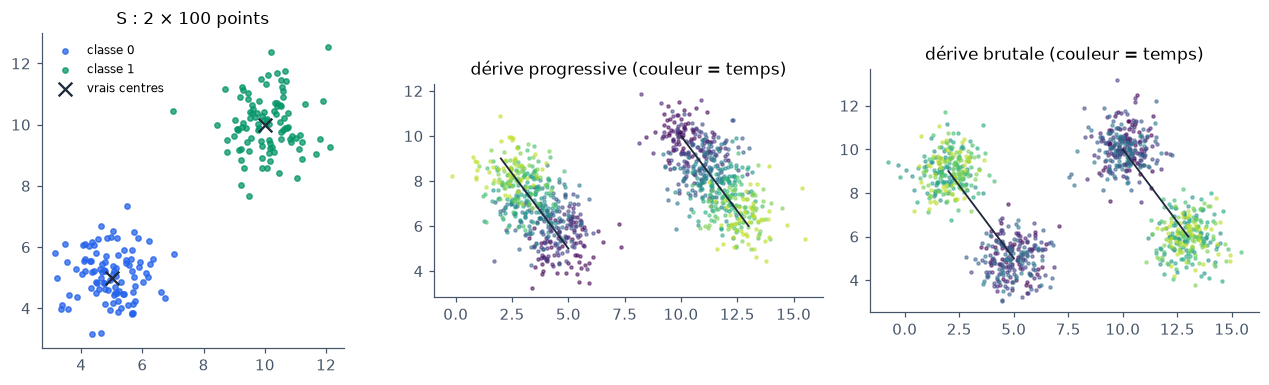

In [4]:
N_BATCHES, BATCH_SIZE = 60, 100
DRIFT_END = np.array([[2.0, 9.0], [13.0, 6.0]])   # positions finales : les deux nuages ne se croisent jamais

def drift_centers(t, kind, n_batches=N_BATCHES):
    # Vrais centres au batch t.
    if kind == "stationary":
        return TRUE_CENTERS.copy()
    if kind == "progressive":
        s = t / (n_batches - 1)
        return TRUE_CENTERS + s * (DRIFT_END - TRUE_CENTERS)
    if kind == "abrupt":
        return TRUE_CENTERS.copy() if t < n_batches // 2 else DRIFT_END.copy()
    raise ValueError(kind)

def make_stream(kind, n_batches=N_BATCHES, b=BATCH_SIZE, seed=SEED):
    # Renvoie la liste des batches (ids, X, y). Les ids sont globaux et croissants, comme un horodatage.
    rng = np.random.default_rng([seed, ["stationary", "progressive", "abrupt"].index(kind)])
    batches = []
    for t in range(n_batches):
        y = rng.integers(0, K, b)
        X = (drift_centers(t, kind)[y] + rng.normal(0, SIGMA, (b, 2))).round(6)
        batches.append((np.arange(t * b, (t + 1) * b), X, y))
    return batches

STREAMS = {kind: make_stream(kind) for kind in ("stationary", "progressive", "abrupt")}
KIND_FR = {"stationary": "stationnaire", "progressive": "progressive", "abrupt": "brutale"}

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
ax = axes[0]
for c in (0, 1):
    m = dfS.label == c
    ax.scatter(dfS.x0[m], dfS.x1[m], s=12, color=COL[f"c{c}"], alpha=.75, label=f"classe {c}")
ax.scatter(*TRUE_CENTERS.T, marker="x", s=80, color=COL["truth"], label="vrais centres")
ax.set_title("S : 2 × 100 points"); ax.legend(loc="upper left", fontsize=8); ax.set_aspect("equal")
for ax, kind in zip(axes[1:], ("progressive", "abrupt")):
    for t in range(0, N_BATCHES, 6):
        _, X, y = STREAMS[kind][t]
        ax.scatter(X[:, 0], X[:, 1], s=4, color=plt.cm.viridis(t / N_BATCHES), alpha=.5)
    path = np.array([drift_centers(t, kind) for t in range(N_BATCHES)])
    for j in (0, 1):
        ax.plot(path[:, j, 0], path[:, j, 1], color=COL["truth"], lw=1.2)
    ax.set_title(f"dérive {KIND_FR[kind]} (couleur = temps)"); ax.set_aspect("equal")
plt.tight_layout(); savefig("data"); plt.show()

## A. K-means séquentiel en Python

### A.1-A.2 Générer et lire en consommant peu de mémoire

La génération est faite plus haut (`write_points_csv`, par blocs). Pour la lecture, `iter_points` est un
générateur : à chaque instant il n'existe qu'une ligne et un point en mémoire. Je le compare à la lecture
habituelle `pd.read_csv`, qui charge tout le fichier. Le calcul mesuré est le même dans les deux cas (la moyenne
des points), seule la façon de lire change.

In [5]:
def mean_streaming(path):
    n, s = 0, None
    for x in iter_points(path):
        s = x[:] if s is None else [a + b for a, b in zip(s, x)]
        n += 1
    return [v / n for v in s]

def mean_in_memory(path):
    X = pd.read_csv(path).iloc[:, 1:-1].to_numpy()
    return X.mean(axis=0).tolist()

rows = []
for n in SIZES:
    (m1, p1), (m2, p2) = peak_memory(mean_streaming, L_PATHS[n]), peak_memory(mean_in_memory, L_PATHS[n])
    assert np.allclose(m1, m2)
    rows.append({"n": n, "pic flux (Kio)": p1 / 1024, "pic pandas (Kio)": p2 / 1024})
read_mem = pd.DataFrame(rows)
save_result("A_read_memory", read_mem.to_dict("records"))
read_mem.round(1)

,n,pic flux (Kio),pic pandas (Kio)
0,1000,42.4,311.5
1,10000,50.4,972.6
2,100000,51.1,9410.4
3,1000000,51.3,93788.9


### A.3 L'algorithme

L'énoncé décrit l'algorithme de MacQueen. Pour chaque nouveau point $x_i$, on cherche le centre le plus proche
$\mu_j$, puis on met à jour

$$\mu_j \leftarrow \mu_j + \frac{1}{n_j + 1}\,(x_i - \mu_j), \qquad n_j \leftarrow n_j + 1 .$$

Avec cette formule, $\mu_j$ est exactement la **moyenne des points qui lui ont été affectés** (récurrence de la
moyenne). L'état complet tient en $k$ centres et $k$ effectifs : $O(kd)$ en mémoire, quel que soit $n$.

Mes choix :

- **Initialisation.** Les deux options de l'énoncé sont implémentées. `first` prend les $k$ premiers points, sans
  lecture supplémentaire. `random` tire $k$ points uniformément dans le fichier par *échantillonnage réservoir*
  (algorithme R) : une passe de plus, mais toujours $O(k)$ en mémoire. Je n'initialise jamais avec les vrais
  centres (5, 5) et (10, 10), ce que faisait la proposition reçue : ce serait donner la réponse à l'algorithme.
- **Effectifs initiaux à 1.** Chaque centre initial est un vrai point du fichier, je le compte donc comme membre
  de son cluster. Avec $n_j = 0$, le premier point affecté remplacerait purement et simplement le centre.
- **Plusieurs passes (option).** Pour une passe supplémentaire, je garde les centres et je remets les effectifs
  à 1. Si les effectifs continuaient de croître, le pas $1/(n_j+1)$ serait déjà minuscule et la deuxième passe ne
  corrigerait presque rien.
- **Calcul en Python pur.** Pour $d = 2$, une boucle sur des listes est plus rapide que NumPy, dont le surcoût
  par appel domine sur des vecteurs de deux éléments.

In [6]:
def sq_dist(a, b):
    return sum((ai - bi) ** 2 for ai, bi in zip(a, b))

def nearest(centers, x):
    best, best_d = 0, sq_dist(centers[0], x)
    for j in range(1, len(centers)):
        d = sq_dist(centers[j], x)
        if d < best_d:
            best, best_d = j, d
    return best

def macqueen_update(centers, counts, x):
    # Une mise à jour de l'énoncé (A.3.b). Modifie centers et counts en place, renvoie le cluster choisi.
    # La même fonction sert dans la partie D (Beam) : les deux implémentations calculent la même chose.
    j = nearest(centers, x)
    counts[j] += 1
    n = counts[j]
    centers[j] = [c + (xi - c) / n for c, xi in zip(centers[j], x)]
    return j

def reservoir_sample(iterable, k, seed):
    # Algorithme R : k éléments tirés uniformément en une seule passe, mémoire O(k).
    rnd = random.Random(seed)
    sample = []
    for i, x in enumerate(iterable):
        if i < k:
            sample.append(x)
        else:
            j = rnd.randint(0, i)
            if j < k:
                sample[j] = x
    return sample

def sequential_kmeans(path, k=K, init="first", seed=0, n_passes=1, online_path=None, trace=False):
    # K-means séquentiel sur un fichier lu en flux.
    # online_path : écrit, au fil de l'eau, le cluster attribué à chaque point au moment où il est lu.
    if init == "first":
        centers = [x for _, x in zip(range(k), iter_points(path))]
        skip = k
    elif init == "random":
        centers = reservoir_sample(iter_points(path), k, seed)
        skip = 0
    else:
        centers, skip = [list(c) for c in init], 0
    counts = [1] * k
    trajectory = [[c[:] for c in centers]] if trace else None
    out = open(online_path, "w", newline="") if online_path else None
    writer = csv.writer(out) if out else None
    if writer:
        writer.writerow(["id", "cluster_online"])
    for p in range(n_passes):
        if p > 0:
            counts = [1] * k
        last = p == n_passes - 1
        for i, (pid, x, _) in enumerate(iter_points(path, with_meta=True)):
            if p == 0 and i < skip:               # point utilisé comme centre initial
                if writer and last:
                    writer.writerow([pid, i])
                continue
            j = macqueen_update(centers, counts, x)
            if writer and last:
                writer.writerow([pid, j])
            if trace:
                trajectory.append([c[:] for c in centers])
    if out:
        out.close()
    return {"centers": centers, "counts": counts, "trajectory": trajectory}

### A.4 Enregistrer les résultats

Deux sorties, toutes deux écrites ligne par ligne :

1. pendant l'apprentissage, le cluster attribué à chaque point **au moment où il est lu** (`*_online.csv`) ;
2. après l'apprentissage, une seconde lecture du fichier affecte chaque point au **centre final**
   (`*_final.csv`). Les centres et effectifs vont dans un petit fichier JSON.

Les deux affectations ne coïncident pas toujours : un point lu tôt a été comparé à des centres encore approximatifs.
La seconde passe calcule au passage l'ARI, l'inertie et le nombre de points qui ont changé de cluster, sans rien
garder en mémoire.

In [7]:
def write_final_assignments(path, centers, out_path, online_path=None):
    ari, inertia, n, changed = StreamingARI(), 0.0, 0, 0
    online = None
    if online_path:
        fo = open(online_path, newline="")
        online = csv.reader(fo)
        next(online)
    with open(out_path, "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["id", "cluster"])
        for pid, x, lab in iter_points(path, with_meta=True):
            j = nearest(centers, x)
            w.writerow([pid, j])
            ari.add(lab, j)
            inertia += sq_dist(centers[j], x)
            n += 1
            if online is not None:
                changed += int(next(online)[1]) != j
    if online_path:
        fo.close()
    return {"ari": ari.value(), "inertia": inertia, "n": n, "changed": changed}

def run_part_a(path, tag, **kw):
    online = OUT / f"A_{tag}_online.csv"
    model = sequential_kmeans(path, online_path=online, **kw)
    stats = write_final_assignments(path, model["centers"], OUT / f"A_{tag}_final.csv", online)
    with open(OUT / f"A_{tag}_centers.json", "w") as f:
        json.dump({"centers": model["centers"], "counts": model["counts"]}, f)
    return model, stats

model_A, stats_A = run_part_a(S_PATH, "S", trace=True)
print("centres :", np.round(model_A["centers"], 3).tolist(), " effectifs :", model_A["counts"])
print(stats_A)
print(open(OUT / "A_S_final.csv").read()[:60])

centres : [[10.008, 9.969], [4.966, 5.104]]  effectifs : [101, 99]
{'ari': 1.0, 'inertia': 277.20050614274606, 'n': 200, 'changed': 1}
id,cluster
0,1
1,1
2,0
3,1
4,0
5,1
6,1
7,0
8,1
9,0
10,0
11,0


### A.5 Valider la cohérence

Trois références :

- les **vrais centres** de la génération ;
- `sklearn.KMeans` sur toutes les données en mémoire, avec 10 initialisations : c'est la solution que l'on
  voudrait retrouver ;
- l'**ARI** par rapport aux vraies classes : 1 si la partition est parfaite, autour de 0 pour une partition au hasard.

La même série de tests porte ensuite sur l'ordre des données, l'initialisation et le nombre de passes.

In [8]:
X_S = dfS[["x0", "x1"]].to_numpy()
ref_S = KMeans(n_clusters=K, n_init=10, random_state=0).fit(X_S)
REF_CENTERS_S = ref_S.cluster_centers_
save_result("ref_centers_S", REF_CENTERS_S.round(4).tolist())

def summary_A(model, stats):
    return {"ARI": stats["ari"], "écart aux vrais centres": center_error(model["centers"], TRUE_CENTERS),
            "écart à sklearn": center_error(model["centers"], REF_CENTERS_S), "inertie": stats["inertia"],
            "points changés (2e passe)": stats["changed"]}

cases = {"S mélangé, init first, 1 passe": run_part_a(S_PATH, "S")}
cases["S trié par classe, init first, 1 passe"] = run_part_a(S_SORTED_PATH, "Ssorted")
cases["S trié par classe, init first, 3 passes"] = run_part_a(S_SORTED_PATH, "Ssorted3", n_passes=3)
table_A = pd.DataFrame({name: summary_A(*v) for name, v in cases.items()}).T
table_A.loc["sklearn (référence, tout en mémoire)"] = [adjusted_rand_score(dfS.label, ref_S.labels_),
                                                      center_error(REF_CENTERS_S, TRUE_CENTERS), 0.0,
                                                      ref_S.inertia_, np.nan]
save_result("A_table", table_A.round(4).reset_index().to_dict("records"))
save_result("A_S", {"centers": np.round(model_A["centers"], 4).tolist(), **{k: round(float(v), 4) for k, v in summary_A(model_A, stats_A).items()}})
table_A.round(3)

,ARI,écart aux vrais centres,écart à sklearn,inertie,points changés (2e passe)
"S mélangé, init first, 1 passe",1.00,0.071,0.040,277.201,1.0
"S trié par classe, init first, 1 passe",0.98,1.864,1.848,1146.281,67.0
"S trié par classe, init first, 3 passes",1.00,0.090,0.000,276.650,0.0
"sklearn (référence, tout en mémoire)",1.00,0.090,0.000,276.650,NaN


In [9]:
seeds = range(20)
rand_runs = []
for s in seeds:
    m, st = run_part_a(S_PATH, f"rand{s}", init="random", seed=s)
    rand_runs.append({"graine": s, "ARI": st["ari"], "écart à sklearn": center_error(m["centers"], REF_CENTERS_S)})
rand_df = pd.DataFrame(rand_runs)
save_result("A_random_init", {"n_seeds": len(rand_df), "ari_min": rand_df.ARI.min(), "ari_median": rand_df.ARI.median(),
                              "err_max": rand_df["écart à sklearn"].max()})
rand_df.describe().loc[["mean", "min", "50%", "max"]].round(4)

,graine,ARI,écart à sklearn
mean,9.5,1.0,0.0358
min,0.0,1.0,0.0062
50%,9.5,1.0,0.0155
max,19.0,1.0,0.1834


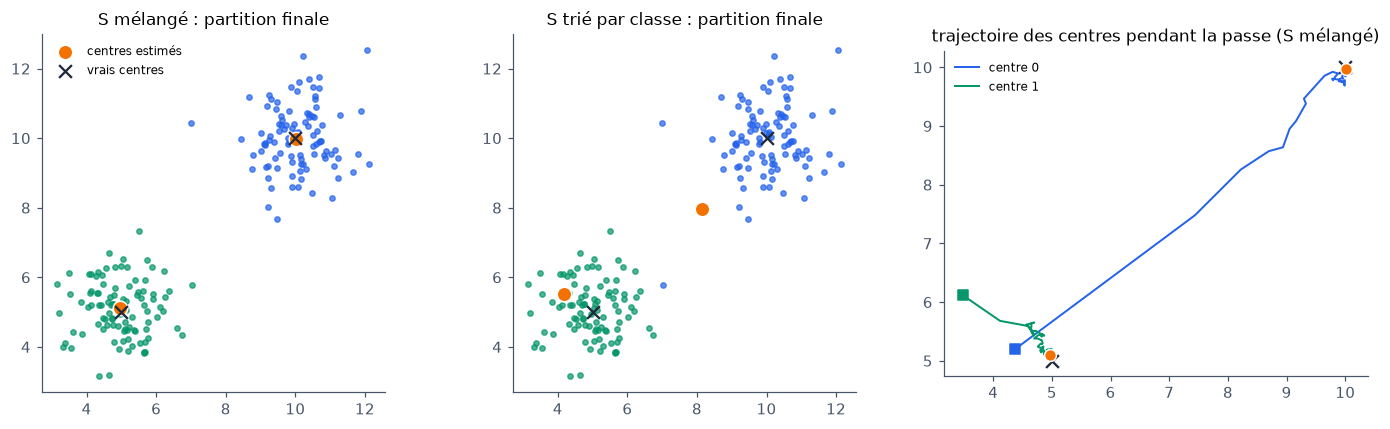

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
traj = np.array(model_A["trajectory"])
final = pd.read_csv(OUT / "A_S_final.csv").merge(dfS, on="id")
for ax, (title, path, tag) in zip(axes[:2], [("S mélangé : partition finale", S_PATH, "S"),
                                             ("S trié par classe : partition finale", S_SORTED_PATH, "Ssorted")]):
    pts = pd.read_csv(path)
    lab = pd.read_csv(OUT / f"A_{tag}_final.csv")
    pts = pts.merge(lab, on="id")
    for c in (0, 1):
        m = pts.cluster == c
        ax.scatter(pts.x0[m], pts.x1[m], s=12, color=COL[f"c{c}"], alpha=.7)
    cen = json.load(open(OUT / f"A_{tag}_centers.json"))["centers"]
    ax.scatter(*np.array(cen).T, marker="o", s=90, color=COL["center"], edgecolor="white", zorder=3, label="centres estimés")
    ax.scatter(*TRUE_CENTERS.T, marker="x", s=70, color=COL["truth"], zorder=3, label="vrais centres")
    ax.set_title(title); ax.set_aspect("equal")
axes[0].legend(loc="upper left", fontsize=8)
ax = axes[2]
for j in range(K):
    ax.plot(traj[:, j, 0], traj[:, j, 1], color=COL[f"c{j}"], lw=1.3, label=f"centre {j}")
    ax.scatter(*traj[0, j], color=COL[f"c{j}"], marker="s", s=40)
    ax.scatter(*traj[-1, j], color=COL["center"], marker="o", s=60, edgecolor="white", zorder=3)
ax.scatter(*TRUE_CENTERS.T, marker="x", s=70, color=COL["truth"])
ax.set_title("trajectoire des centres pendant la passe (S mélangé)"); ax.legend(fontsize=8); ax.set_aspect("equal")
plt.tight_layout(); savefig("A_validation"); plt.show()

**Montée en volume.** Je lance la partie A complète (apprentissage, puis seconde passe d'écriture) de $10^3$ à
$10^6$ points. Le temps est mesuré sans `tracemalloc`, qui ralentit l'exécution ; le pic de mémoire est mesuré
dans une seconde exécution. Pour comparaison, je mesure aussi le pic d'une version « tout en mémoire »
(lecture `pandas` puis `sklearn.KMeans`).

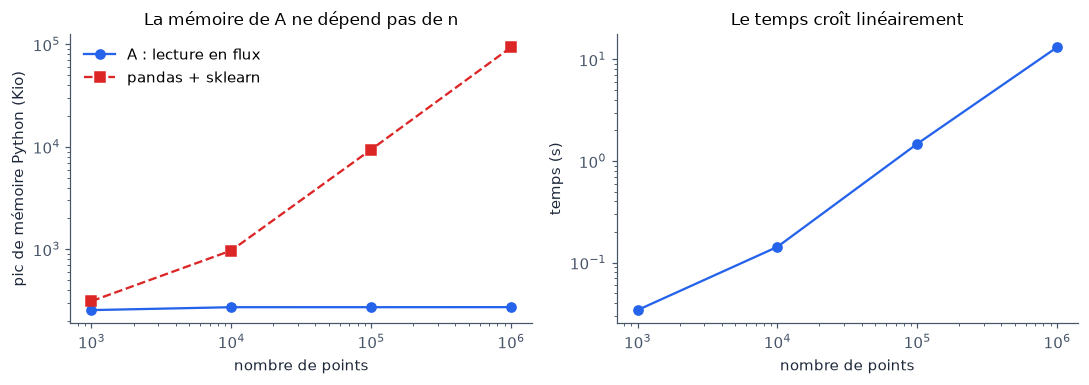

,n,temps A (s),pic A (Kio),pic tout en mémoire (Kio),ARI A,écart A / sklearn
0,1000,0.034,254.394,311.261,1.0,0.0
1,10000,0.143,271.549,971.818,1.0,0.0
2,100000,1.477,271.603,9409.834,1.0,0.0
3,1000000,13.174,271.928,93787.311,1.0,0.0


In [11]:
def part_a_full(path, tag):
    return run_part_a(path, tag)

def in_memory_kmeans(path):
    X = pd.read_csv(path).iloc[:, 1:-1].to_numpy()
    return KMeans(n_clusters=K, n_init=1, random_state=0).fit(X).cluster_centers_

scale_rows = []
for n in SIZES:
    t0 = time.perf_counter(); (m, st) = part_a_full(L_PATHS[n], f"L{n}"); dt = time.perf_counter() - t0
    _, peak = peak_memory(part_a_full, L_PATHS[n], f"L{n}")
    t1 = time.perf_counter(); c_mem, peak_mem = peak_memory(in_memory_kmeans, L_PATHS[n]); dt_mem = time.perf_counter() - t1
    scale_rows.append({"n": n, "temps A (s)": dt, "pic A (Kio)": peak / 1024, "pic tout en mémoire (Kio)": peak_mem / 1024,
                       "ARI A": st["ari"], "écart A / sklearn": center_error(m["centers"], c_mem)})
scale_A = pd.DataFrame(scale_rows)
save_result("A_scaling", scale_A.round(4).to_dict("records"))
assert scale_A["pic A (Kio)"].max() < 4 * scale_A["pic A (Kio)"].min(), "la mémoire de A ne doit pas croître avec n"

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].loglog(scale_A.n, scale_A["pic A (Kio)"], "o-", color=COL["A"], label="A : lecture en flux")
axes[0].loglog(scale_A.n, scale_A["pic tout en mémoire (Kio)"], "s--", color=COL["error"], label="pandas + sklearn")
axes[0].set_xlabel("nombre de points"); axes[0].set_ylabel("pic de mémoire Python (Kio)"); axes[0].legend()
axes[0].set_title("La mémoire de A ne dépend pas de n")
axes[1].loglog(scale_A.n, scale_A["temps A (s)"], "o-", color=COL["A"])
axes[1].set_xlabel("nombre de points"); axes[1].set_ylabel("temps (s)"); axes[1].set_title("Le temps croît linéairement")
plt.tight_layout(); savefig("A_scaling"); plt.show()
scale_A.round(3)

**Ce que je retiens de la partie A** (les chiffres sont dans les tableaux ci-dessus) :

- Sur `S` mélangé, une seule passe suffit à retrouver la partition et des centres très proches de ceux de
  `sklearn`. C'est attendu : chaque centre est la moyenne des points qu'il a reçus, et presque tous les points
  ont été envoyés du bon côté.
- Sur les mêmes points **triés par classe**, le résultat se dégrade nettement : les deux centres initiaux sont dans
  le même nuage, et le centre qui finit par « migrer » vers (10, 10) garde dans sa moyenne les points de (5, 5)
  reçus au début. Repasser sur les données corrige le biais, ce qui illustre la remarque de la partie B de l'énoncé.
- L'initialisation aléatoire par réservoir donne le même résultat pour les 20 graines sur ce jeu bien séparé.
- Le pic de mémoire de A reste plat de $10^3$ à $10^6$ points, alors que la version « tout en mémoire » croît
  linéairement. Le temps croît linéairement : chaque point coûte $O(kd)$.

**Limites.** Le résultat dépend de l'ordre des données, et le pas $1/n_j$ finit par figer les centres : c'est
exactement ce qui pose problème quand la distribution change (partie B). L'algorithme est aussi intrinsèquement
séquentiel : le traitement du point $i$ dépend des centres laissés par le point $i-1$.

## B. K-means en streaming sur les T derniers batches

### Ce que dit l'énoncé, et une contradiction à lever

On garde au plus $T$ batches en mémoire. À l'arrivée d'un batch $B^0$ : on retire le plus ancien si on en a déjà
$T$, on ajoute $B^0$, on initialise les centres **avec la partition $P$ des batches précédents**, puis on lance un
k-means pondéré où les points du batch d'âge $t$ ($t = 0$ pour le plus récent) pèsent $r^t$.

L'énoncé dit aussi que « plus $r$ est grand, moins les anciens batches pèsent ». Avec $w_t = r^t$, c'est
l'inverse dès que $r < 1$ : $r = 0{,}9$ garde beaucoup d'historique, $r = 0{,}2$ l'oublie presque aussitôt, et
$r > 1$ donnerait *plus* de poids aux vieux batches. J'implémente la formule $w_t = r^t$, que je considère comme
la définition, et je teste $r \in (0, 1]$ ainsi que $r = 2$. La phrase de l'énoncé correspond à
$w_t = r^{-t}$, c'est-à-dire au paramètre $r' = 1/r$.

### Choix d'implémentation

- **Initialisation par $P$.** Les centres de départ sont les barycentres pondérés des batches déjà partitionnés
  ($B^0$ n'a pas encore de partition). Au tout premier batch, $P$ est tirée au hasard, comme le demande l'énoncé.
  Si un cluster est vide après le retrait du plus vieux batch, il garde son centre précédent.
- **Fonction pure.** `streaming_update(état, id, batch)` renvoie un nouvel état sans rien modifier. C'est la
  même fonction qui tourne dans le `DoFn` de la partie E, ce qui permet de vérifier que B et E donnent exactement
  la même chose.
- **Batches repérés par un identifiant.** Un batch déjà vu est ignoré, et un batch plus ancien que toute la fenêtre
  est écarté. En Python séquentiel cela ne sert à rien, mais dans Beam un batch peut être rejoué après une panne
  ou arriver en retard (partie E).
- **Aléatoire reproductible.** La partition aléatoire initiale dépend de `(graine, id du batch)`, pas d'un
  générateur global dont l'état changerait selon l'ordre des appels.

**Mémoire** : $T$ batches de $b$ points en dimension $d$, plus leurs étiquettes, soit $O(T\,b\,d)$. La mémoire est
bornée tant que les batches ont une taille bornée ; elle ne dépend plus de la longueur du flux.

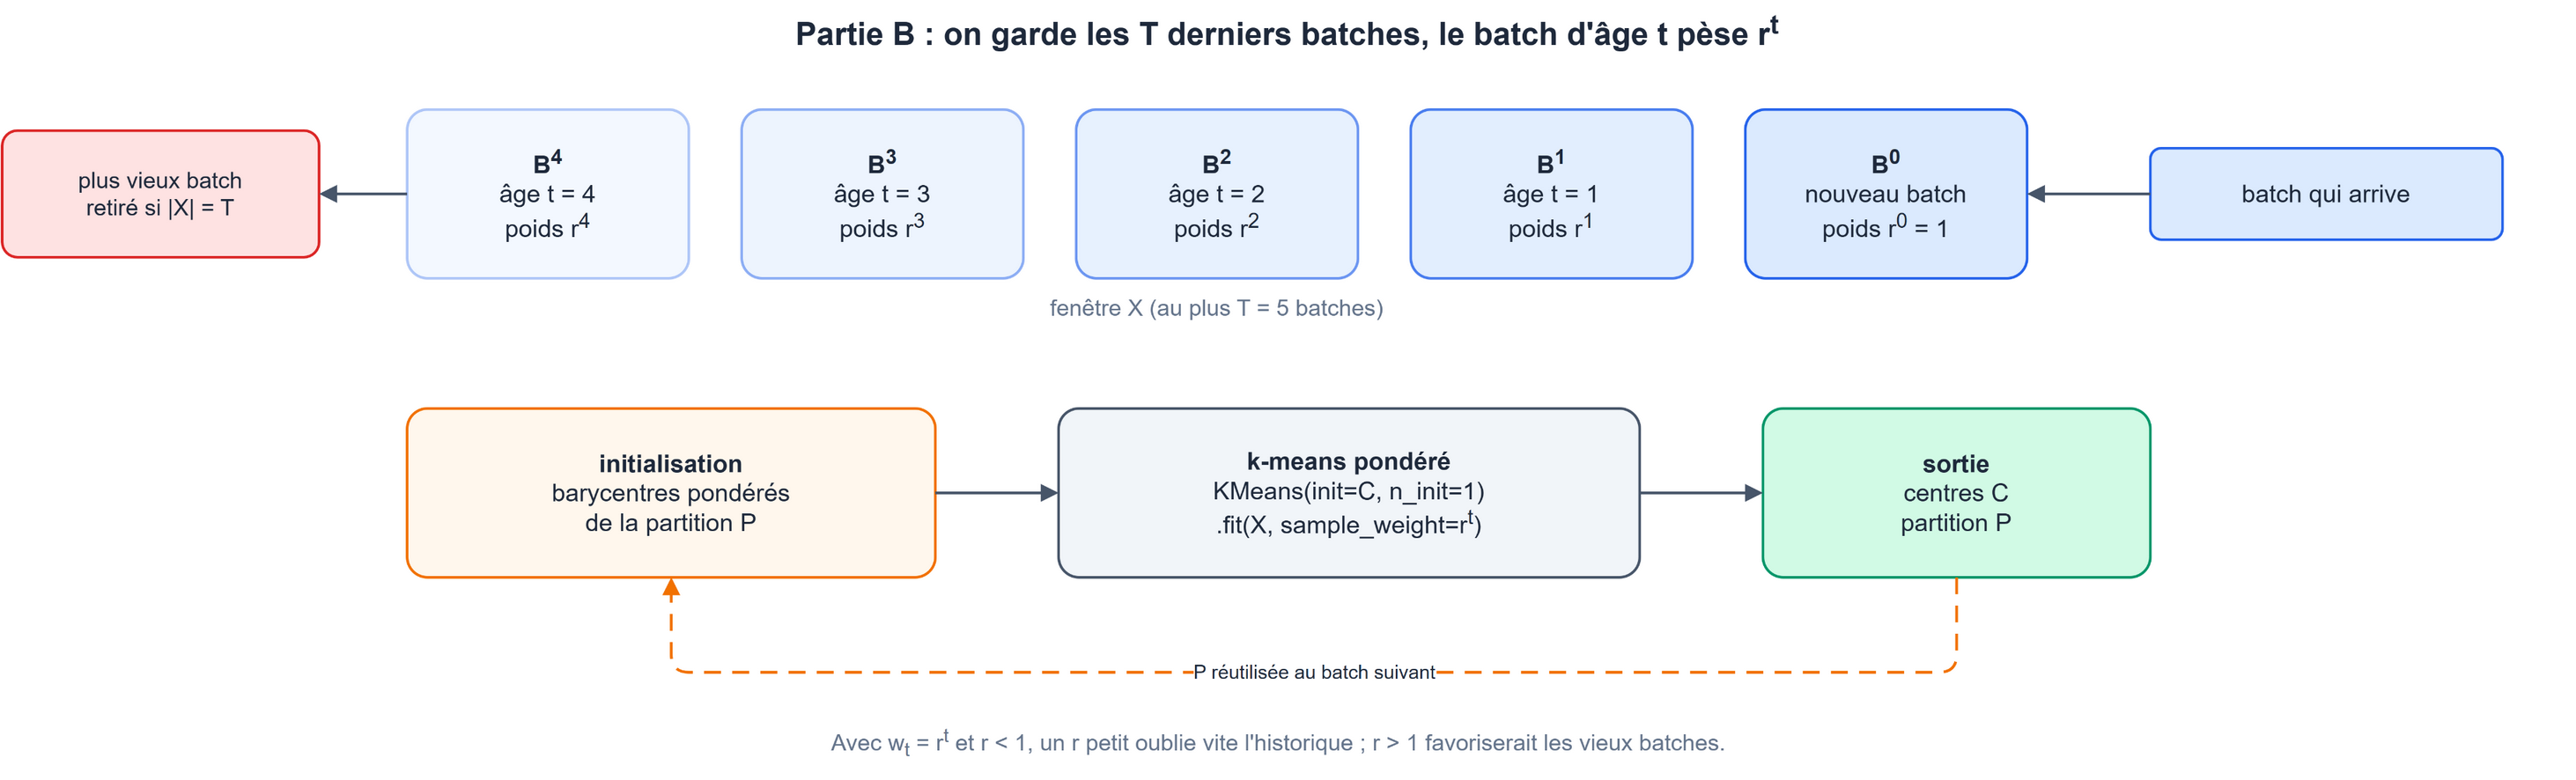

In [12]:
show_diagram("01_streaming_window")

In [13]:
def weighted_partition_means(batches, labels, weights, k, fallback):
    d = batches[0].shape[1]
    S, W = np.zeros((k, d)), np.zeros(k)
    for X, P, w in zip(batches, labels, weights):
        Sb = np.zeros((k, d)); np.add.at(Sb, P, X)
        S += w * Sb
        W += w * np.bincount(P, minlength=k)
    C = np.empty((k, d))
    for j in range(k):
        C[j] = S[j] / W[j] if W[j] > 0 else fallback[j]
    return C


def empty_state():
    return {"ids": [], "batches": [], "labels": [], "centers": None}


def streaming_update(state, batch_id, batch, k=K, T=5, r=0.5, seed=SEED):
    # Une étape de l'algorithme de la partie B. Renvoie (nouvel_état, centres C, partition du nouveau batch).
    batch = np.asarray(batch, dtype=float)
    ids = list(state["ids"])
    if batch_id in ids:                                   # batch déjà traité : on ne change rien (idempotence)
        return state, state["centers"], None
    if len(ids) == T and batch_id < ids[0]:               # plus ancien que toute la fenêtre : écarté
        return state, state["centers"], None
    batches, labels = list(state["batches"]), list(state["labels"])
    if len(ids) == T:                                     # 1. retirer le plus vieux batch
        ids.pop(0); batches.pop(0); labels.pop(0)
    pos = int(np.searchsorted(ids, batch_id))             # 2. ajouter B0 (à sa place si arrivé en désordre)
    ids.insert(pos, batch_id); batches.insert(pos, batch); labels.insert(pos, None)
    ages = [len(ids) - 1 - i for i in range(len(ids))]    # 0 pour le plus récent
    weights = [r ** a for a in ages]
    known = [i for i, P in enumerate(labels) if P is not None]
    if known:                                             # 3. initialiser C avec la partition P
        C0 = weighted_partition_means([batches[i] for i in known], [labels[i] for i in known],
                                      [weights[i] for i in known], k, fallback=state["centers"])
    else:                                                 #    pas de batch précédent : P aléatoire
        P0 = np.random.default_rng([seed, int(batch_id)]).integers(0, k, len(batch))
        C0 = weighted_partition_means([batch], [P0], [1.0], k, fallback=batch[:k])
    X = np.vstack(batches)                                # 4. k-means pondéré (scikit-learn, sample_weight)
    w = np.concatenate([np.full(len(b), wt) for b, wt in zip(batches, weights)])
    km = KMeans(n_clusters=k, init=C0, n_init=1, algorithm="lloyd").fit(X, sample_weight=w)
    parts = np.split(km.labels_, np.cumsum([len(b) for b in batches])[:-1])
    new_state = {"ids": ids, "batches": batches, "labels": parts, "centers": km.cluster_centers_}
    return new_state, km.cluster_centers_, parts[pos]


class StreamingWeightedKMeans:
    # Enveloppe orientée objet : garde l'état entre deux appels à partial_fit.
    def __init__(self, k=K, T=5, r=0.5, seed=SEED):
        self.k, self.T, self.r, self.seed = k, T, r, seed
        self.state = empty_state()

    def partial_fit(self, batch_id, batch):
        self.state, C, P = streaming_update(self.state, batch_id, batch, self.k, self.T, self.r, self.seed)
        return C, P

    def window_points(self):
        return sum(len(b) for b in self.state["batches"])

### Test 1 : flux stationnaire et cohérence des numéros de cluster

Sur un flux qui ne bouge pas, la méthode doit retrouver les deux centres, et un cluster doit garder **le même
numéro** d'un batch à l'autre. Comme l'initialisation part de la partition précédente, c'est attendu ; je le
vérifie en comptant les batches où les centres auraient « échangé » leurs numéros.

In [14]:
def run_streaming(kind, T=5, r=0.5, seed=SEED):
    model = StreamingWeightedKMeans(T=T, r=r, seed=seed)
    hist, errs, swaps, times = [], [], 0, []
    for t, (ids, X, y) in enumerate(STREAMS[kind]):
        t0 = time.perf_counter(); C, P = model.partial_fit(t, X); times.append(time.perf_counter() - t0)
        if hist:
            prev = hist[-1]
            same = np.linalg.norm(C - prev, axis=1).sum()
            swapped = np.linalg.norm(C[::-1] - prev, axis=1).sum()
            swaps += int(swapped < same)
        hist.append(C.copy())
        errs.append(center_error(C, drift_centers(t, kind)))
    return {"centers": np.array(hist), "errors": np.array(errs), "swaps": swaps,
            "ms_per_batch": 1000 * np.mean(times), "window_points": model.window_points(), "model": model}

def run_sequential_on_stream(kind):
    # Partie A appliquée au même flux, point par point (init : k premiers points du premier batch).
    first = STREAMS[kind][0][1]
    centers, counts = [list(x) for x in first[:K]], [1] * K
    hist, errs = [], []
    for t, (ids, X, y) in enumerate(STREAMS[kind]):
        for i, x in enumerate(X.tolist()):
            if t == 0 and i < K:
                continue
            macqueen_update(centers, counts, x)
        hist.append(np.array(centers)); errs.append(center_error(centers, drift_centers(t, kind)))
    return {"centers": np.array(hist), "errors": np.array(errs)}

stat_B = run_streaming("stationary")
print("échanges de numéros :", stat_B["swaps"], "| erreur moyenne aux vrais centres :", stat_B["errors"].mean().round(4),
      "| points en mémoire :", stat_B["window_points"], "| ms par batch :", round(stat_B["ms_per_batch"], 1))
assert stat_B["swaps"] == 0
save_result("B_stationary", {"swaps": stat_B["swaps"], "mean_error": float(stat_B["errors"].mean()),
                             "window_points": stat_B["window_points"], "ms_per_batch": float(stat_B["ms_per_batch"])})

échanges de numéros : 0 | erreur moyenne aux vrais centres : 0.0873 | points en mémoire : 500 | ms par batch : 5.6


### Test 2 : dérive progressive et rupture brutale

Je compare la partie B ($T = 5$, $r = 0{,}5$) à la partie A appliquée au même flux point par point. L'erreur de
suivi est la distance moyenne entre les centres estimés après le batch $t$ et les vrais centres au batch $t$.

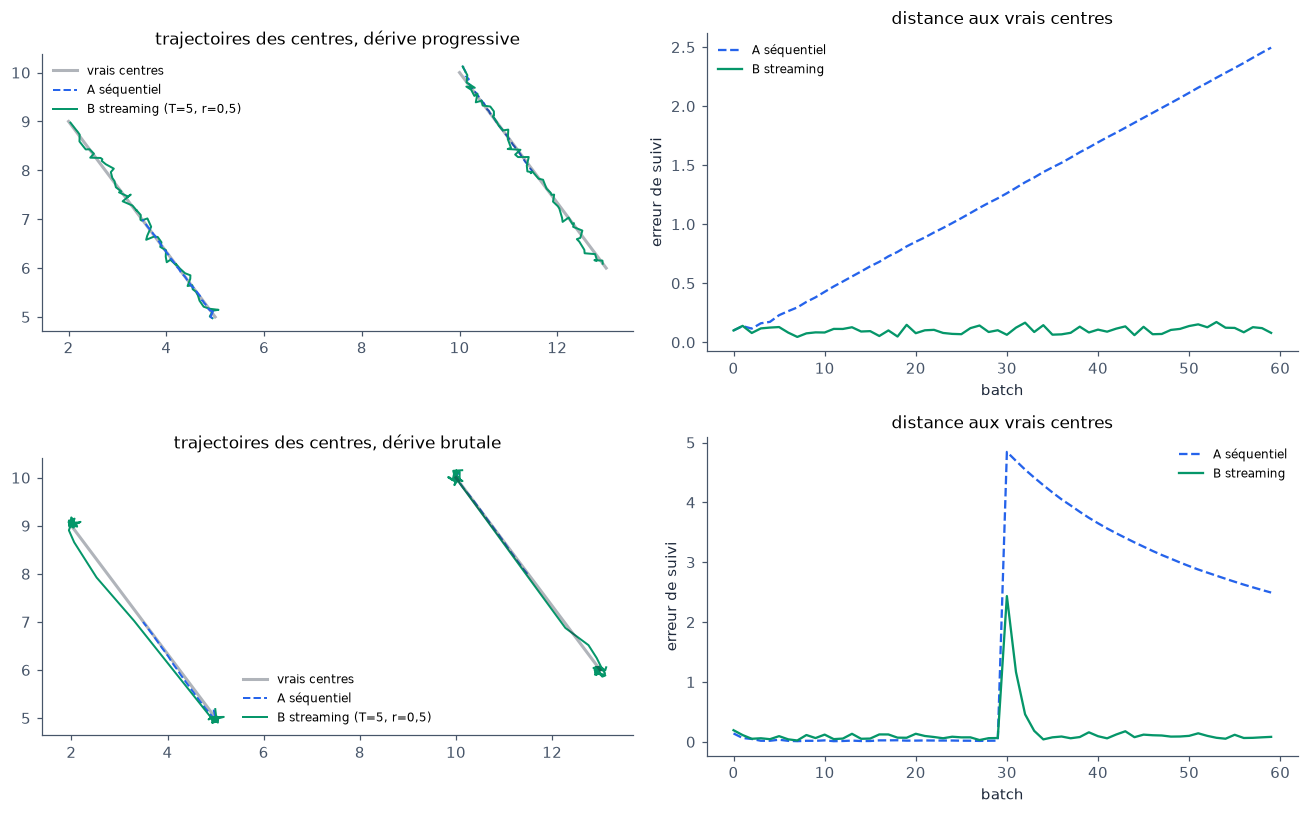

,A : erreur moyenne (10 derniers batches),B : erreur moyenne (10 derniers batches)
progressive,2.304,0.125
abrupt,2.705,0.087


In [15]:
drift_runs = {}
for kind in ("progressive", "abrupt"):
    drift_runs[kind] = {"A": run_sequential_on_stream(kind), "B": run_streaming(kind, T=5, r=0.5)}

fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
for row, kind in enumerate(("progressive", "abrupt")):
    runs = drift_runs[kind]
    ax = axes[row, 0]
    truth = np.array([drift_centers(t, kind) for t in range(N_BATCHES)])
    for j in range(K):
        ax.plot(truth[:, j, 0], truth[:, j, 1], color=COL["truth"], lw=2, alpha=.35, label="vrais centres" if j == 0 else None)
        ax.plot(runs["A"]["centers"][:, j, 0], runs["A"]["centers"][:, j, 1], "--", color=COL["A"], lw=1.3,
                label="A séquentiel" if j == 0 else None)
        ax.plot(runs["B"]["centers"][:, j, 0], runs["B"]["centers"][:, j, 1], color=COL["B"], lw=1.3,
                label="B streaming (T=5, r=0,5)" if j == 0 else None)
    ax.set_title(f"trajectoires des centres, dérive {KIND_FR[kind]}"); ax.set_aspect("equal"); ax.legend(fontsize=8)
    ax = axes[row, 1]
    ax.plot(runs["A"]["errors"], "--", color=COL["A"], label="A séquentiel")
    ax.plot(runs["B"]["errors"], color=COL["B"], label="B streaming")
    ax.set_xlabel("batch"); ax.set_ylabel("erreur de suivi"); ax.set_title("distance aux vrais centres"); ax.legend(fontsize=8)
plt.tight_layout(); savefig("B_drift"); plt.show()

drift_summary = {kind: {m: float(drift_runs[kind][m]["errors"][-10:].mean()) for m in ("A", "B")} for kind in drift_runs}
save_result("B_drift_last10", drift_summary)
pd.DataFrame(drift_summary).T.rename(columns={"A": "A : erreur moyenne (10 derniers batches)",
                                              "B": "B : erreur moyenne (10 derniers batches)"}).round(3)

### Test 3 : effet de T et de r

Sur la dérive progressive, je fais varier la taille de la fenêtre $T$ et le facteur $r$. Pour chaque couple, je
mesure l'erreur moyenne de suivi (hors 5 premiers batches), le temps par batch et le nombre de points gardés.

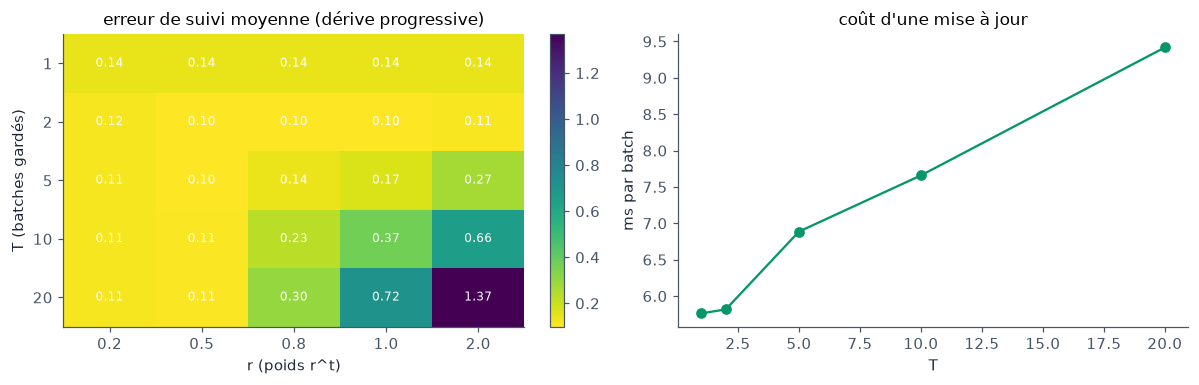

r,0.2,0.5,0.8,1.0,2.0
T,,,,,
1,0.139,0.139,0.139,0.139,0.139
2,0.118,0.104,0.099,0.099,0.110
5,0.114,0.102,0.138,0.171,0.269
10,0.114,0.108,0.231,0.369,0.663
20,0.114,0.109,0.300,0.720,1.369


In [16]:
grid = []
for T in (1, 2, 5, 10, 20):
    for r in (0.2, 0.5, 0.8, 1.0, 2.0):
        run = run_streaming("progressive", T=T, r=r)
        grid.append({"T": T, "r": r, "erreur": float(run["errors"][5:].mean()),
                     "ms/batch": float(run["ms_per_batch"]), "points en mémoire": run["window_points"]})
grid_df = pd.DataFrame(grid)
save_result("B_grid", grid_df.round(4).to_dict("records"))
pivot = grid_df.pivot(index="T", columns="r", values="erreur")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
im = axes[0].imshow(pivot.values, cmap="viridis_r", aspect="auto")
axes[0].set_xticks(range(len(pivot.columns)), [str(c) for c in pivot.columns]); axes[0].set_yticks(range(len(pivot.index)), pivot.index)
axes[0].set_xlabel("r (poids r^t)"); axes[0].set_ylabel("T (batches gardés)")
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        axes[0].text(j, i, f"{pivot.values[i, j]:.2f}", ha="center", va="center", color="white", fontsize=8)
axes[0].set_title("erreur de suivi moyenne (dérive progressive)")
plt.colorbar(im, ax=axes[0], fraction=.046)
t_ms = grid_df.groupby("T")["ms/batch"].mean()
axes[1].plot(t_ms.index, t_ms.values, "o-", color=COL["B"])
axes[1].set_xlabel("T"); axes[1].set_ylabel("ms par batch"); axes[1].set_title("coût d'une mise à jour")
plt.tight_layout(); savefig("B_grid"); plt.show()
pivot.round(3)

**Ce que je retiens de la partie B.** La partie A ne suit pas la dérive : son pas $1/n_j$ devient minuscule, et
ses centres restent près de la moyenne de tout ce qu'elle a vu. La version streaming suit les centres avec un
léger retard, et se recale en quelques batches après la rupture brutale. La grille montre le compromis attendu :
une fenêtre courte ou un $r$ petit réagit vite mais estime sur peu de points (plus de bruit) ; une fenêtre longue
avec $r$ proche de 1 lisse le bruit mais traîne derrière la dérive. $r = 2$, qui favorise les vieux batches, est
le pire réglage, ce qui confirme qu'il faut lire la formule $r^t$ avec $r < 1$.

**Limites.** Le coût d'une mise à jour croît avec $T\,b$, puisqu'on relance un k-means sur toute la fenêtre. La
mémoire est bornée par $T\,b\,d$, mais elle n'est pas constante comme en A : la fenêtre stocke les points
eux-mêmes. Et l'algorithme reste séquentiel d'un batch au suivant.

## C. K-means distribué avec Apache Beam

Ici, c'est l'algorithme de Lloyd qui se distribue bien, pas celui de MacQueen : à chaque itération, l'affectation
d'un point ne dépend que des centres de l'itération précédente, donc tous les points peuvent être traités en
parallèle. Le calcul des centres est une **agrégation par clé** (somme et effectif par cluster), associative et
commutative.

**Runner.** Le code tourne avec le `DirectRunner` local. Dans la version 2.78 de Beam, celui-ci délègue
l'exécution à *Prism*, un runner portable écrit en Go, qui exécute le code Python dans le même processus. Les
temps mesurés ici décrivent donc une seule machine et le coût fixe de lancement d'un pipeline, pas un cluster.
Le même code tournerait sans modification sur Dataflow, Flink ou Spark.

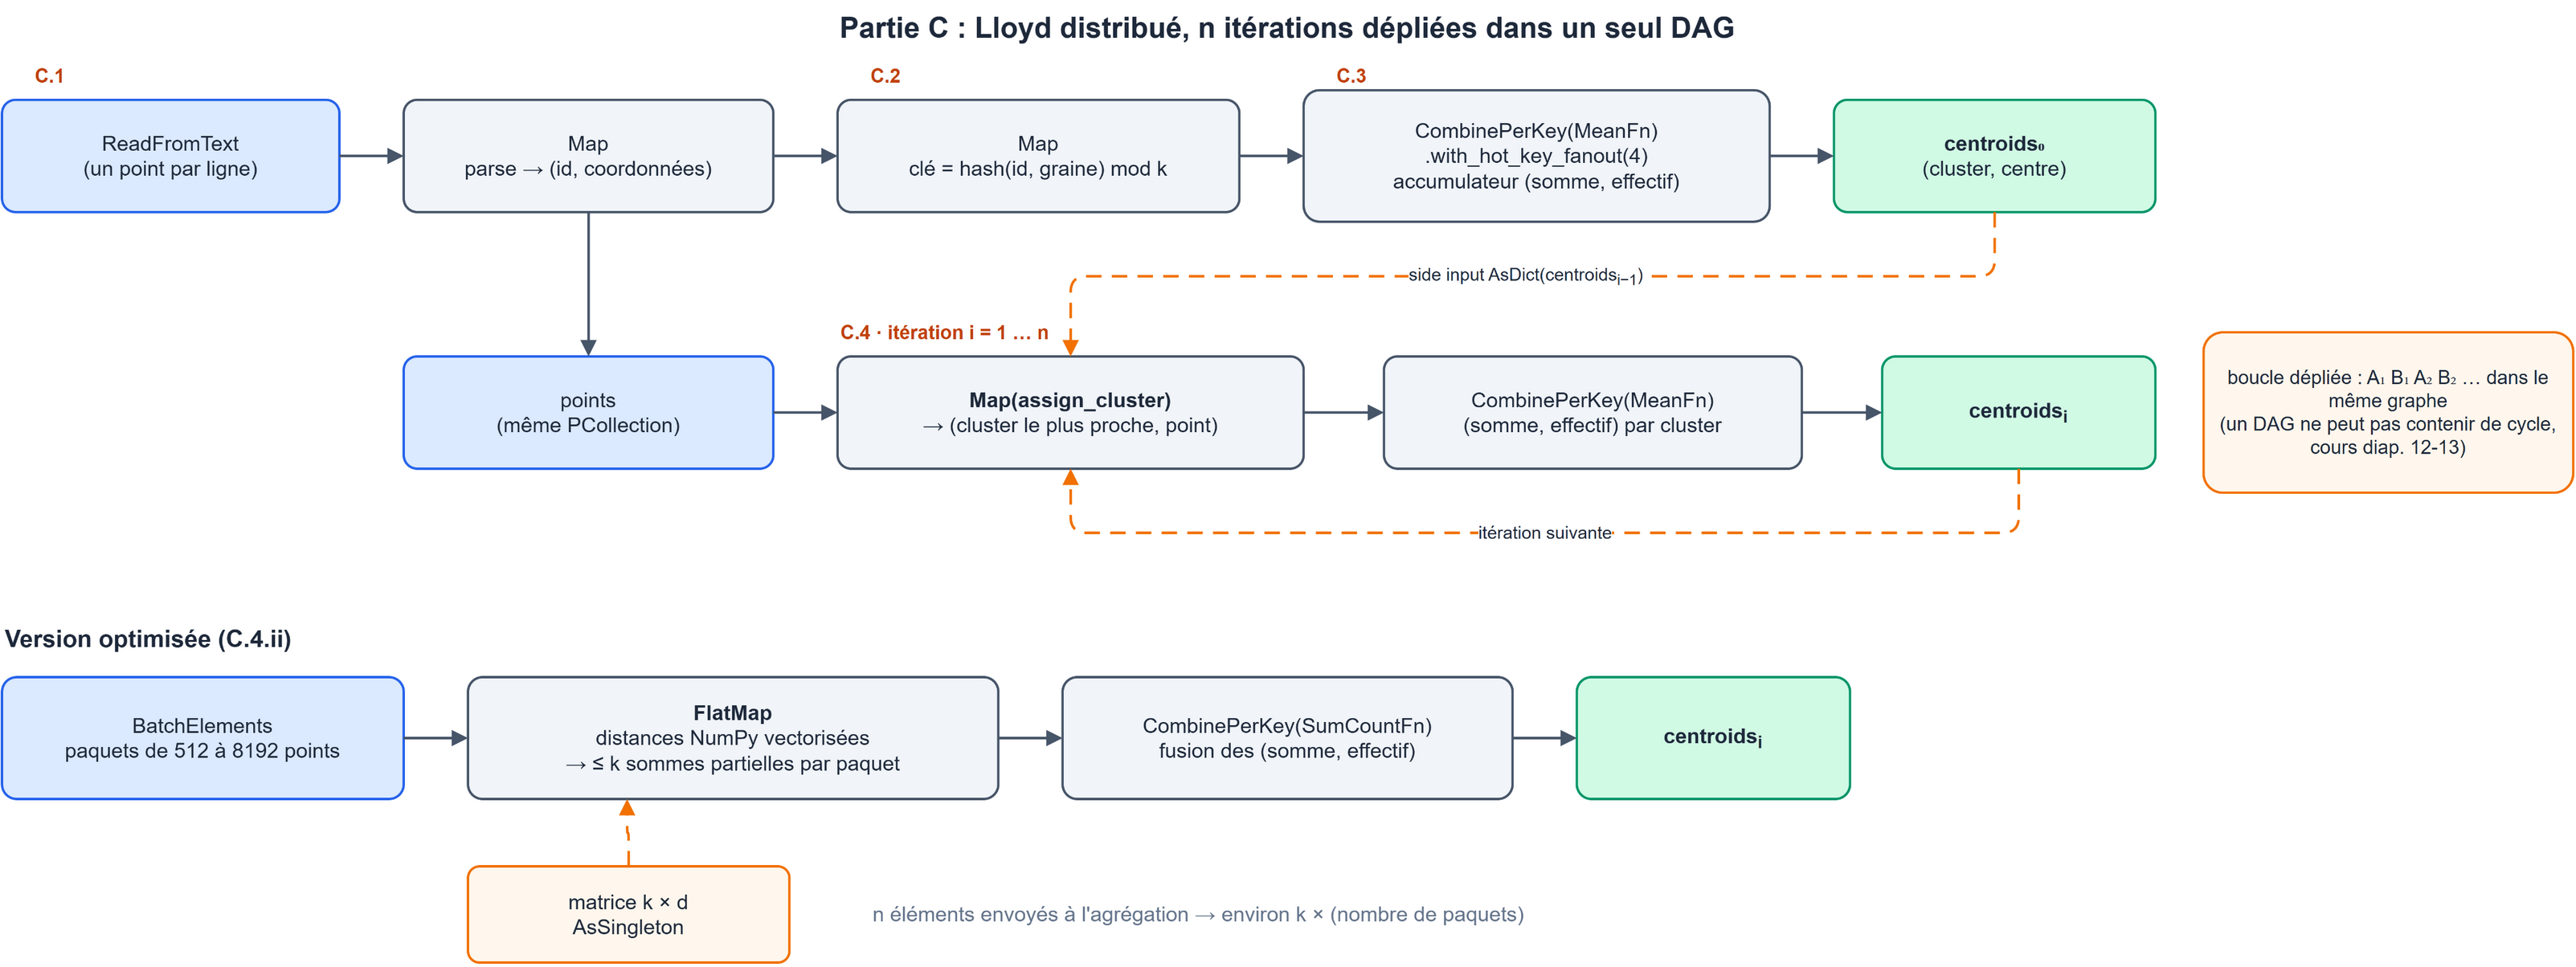

In [17]:
show_diagram("02_beam_distributed")

In [18]:
def parse_csv_line(line, dim):
    # 'id,x0,x1,label' -> (id, (x0, ..., x_{dim-1}))
    parts = line.split(",")
    return int(parts[0]), tuple(float(v) for v in parts[1:1 + dim])

def init_key(pid, k, seed=SEED):
    # Numéro de cluster « aléatoire » mais déterministe : hachage de (graine, id).
    # Si le runner rejoue un bundle après une panne, le point retombe dans le même cluster (idempotence).
    h = hashlib.blake2b(f"{seed}:{pid}".encode(), digest_size=8).digest()
    return int.from_bytes(h, "big") % k

class MeanFn(beam.CombineFn):
    # Moyenne par cluster. L'accumulateur (somme, effectif) est associatif et commutatif : le runner peut
    # pré-agréger sur chaque worker avant l'échange réseau (combiner lifting), contrairement à GroupByKey.
    def create_accumulator(self):
        return (None, 0)
    def add_input(self, acc, x):
        s, n = acc
        x = np.asarray(x, dtype=float)
        return (x.copy() if s is None else s + x, n + 1)
    def merge_accumulators(self, accs):
        S, N = None, 0
        for s, n in accs:
            if s is not None:
                S = s.copy() if S is None else S + s
                N += n
        return (S, N)
    def extract_output(self, acc):
        s, n = acc
        return tuple((s / n).tolist())

def assign_cluster(point, centroids):
    # Énoncé C.4.a : point = coordonnées, centroids = {numéro: coordonnées}. Renvoie (cluster le plus proche, point).
    best, best_d = None, float("inf")
    for j, c in centroids.items():
        d = sum((a - b) ** 2 for a, b in zip(point, c))
        if d < best_d:
            best, best_d = j, d
    return best, point

def read_points(p, path, dim, label=""):
    return (p | f"{label}lire" >> beam.io.ReadFromText(str(path), skip_header_lines=1)
              | f"{label}parser" >> beam.Map(parse_csv_line, dim=dim))

def write_jsonl(pcoll, path, label=""):
    return (pcoll | f"{label}json" >> beam.Map(json.dumps)
                  | f"{label}ecrire" >> beam.io.WriteToText(str(path), shard_name_template=""))

def read_jsonl(path):
    with open(path) as f:
        return [json.loads(line) for line in f]

### C.1 à C.4, pas à pas, en dimension 1

Je prends la coordonnée `x0` de `S.csv` : 200 valeurs autour de 5 et de 10. Le pipeline ci-dessous fait
exactement les étapes de l'énoncé : PCollection des points (C.1), clé de cluster aléatoire (C.2), PCollection
`centroids` (C.3), puis une étape de partitionnement avec `Map` et les centroïdes en entrée complémentaire sous
forme de dictionnaire (C.4).

In [19]:
with beam.Pipeline() as p:
    points = read_points(p, S_PATH, dim=1)                                                   # C.1
    keyed = points | "C2 clé aléatoire" >> beam.Map(lambda e: (init_key(e[0], K), e[1]))     # C.2
    centroids = keyed | "C3 centres" >> beam.CombinePerKey(MeanFn())                         # C.3
    assigned = points | "C4 partition" >> beam.Map(                                          # C.4
        lambda e, c: assign_cluster(e[1], c), c=beam.pvalue.AsDict(centroids))
    write_jsonl(points | beam.combiners.Count.Globally(), OUT / "C_step_count.jsonl", "n")
    write_jsonl(keyed | "taille init" >> beam.combiners.Count.PerKey(), OUT / "C_step_init_sizes.jsonl", "i")
    write_jsonl(centroids, OUT / "C_step_centroids.jsonl", "c")
    write_jsonl(assigned | "taille après" >> beam.combiners.Count.PerKey(), OUT / "C_step_assigned_sizes.jsonl", "a")

print("C.1 nombre de points            :", read_jsonl(OUT / "C_step_count.jsonl"))
print("C.2 effectifs de l'init. aléatoire :", sorted(read_jsonl(OUT / "C_step_init_sizes.jsonl")))
print("C.3 centroids                   :", sorted(read_jsonl(OUT / "C_step_centroids.jsonl")))
print("C.4 effectifs après partition   :", sorted(read_jsonl(OUT / "C_step_assigned_sizes.jsonl")))

C.1 nombre de points            : [200]
C.2 effectifs de l'init. aléatoire : [[0, 101], [1, 99]]
C.3 centroids                   : [[0, [7.502020059405943]], [1, [7.522586313131313]]]
C.4 effectifs après partition   : [[0, 101], [1, 99]]


Les deux centres initiaux sont presque égaux : la moyenne de 100 points tirés au hasard est proche de la moyenne
globale (7,5 environ). C'est le défaut connu de l'initialisation par partition aléatoire. Sur deux nuages bien
séparés, la première affectation coupe pourtant déjà les données au bon endroit, et les itérations suivantes
convergent.

### Itérer : la boucle dépliée dans un seul DAG

Un pipeline Beam est un graphe orienté **acyclique** : il ne peut pas contenir la boucle de Lloyd. Le cours
(diapositive 13) propose deux solutions. La première **déplie** un nombre fixe d'itérations dans le même graphe
($A_1 B_1 A_2 B_2 \dots$). La seconde laisse un programme externe piloter la boucle, avec un pipeline par
itération. J'implémente les deux. Le code est le même en dimension 1 et en dimension 2, seul `dim` change.

Pour vérifier le résultat, je calcule en Python la même initialisation (mêmes clés hachées), puis je lance
`sklearn.KMeans` depuis ces centres avec le même nombre d'itérations : les centres doivent être identiques.

d=1 : init [[7.502], [7.523]] -> final [[4.98], [10.096]]  | écart max à sklearn 1.8e-15 | ARI 0.980 | 1.7 s | fichiers : ['C_d1_labels-00000-of-00003.csv', 'C_d1_labels-00001-of-00003.csv', 'C_d1_labels-00002-of-00003.csv']


d=2 : init [[7.502, 7.511], [7.523, 7.611]] -> final [[4.96, 5.105], [10.065, 10.016]]  | écart max à sklearn 3.6e-15 | ARI 1.000 | 1.5 s | fichiers : ['C_d2_labels-00000-of-00003.csv', 'C_d2_labels-00001-of-00003.csv', 'C_d2_labels-00002-of-00003.csv']


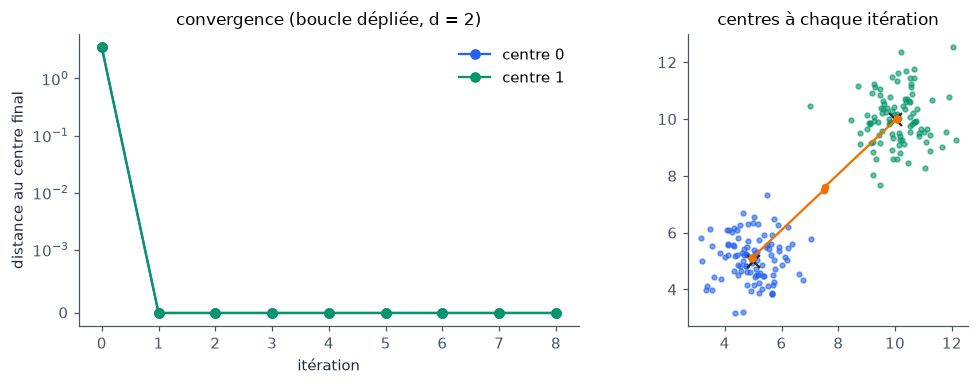

In [20]:
def beam_kmeans_unrolled(path, dim, n_iter=8, k=K, tag="C"):
    # Lloyd distribué, n_iter itérations dépliées dans un seul pipeline. Écrit les centres de chaque itération.
    with beam.Pipeline() as p:
        points = read_points(p, path, dim)
        keyed = points | "init" >> beam.Map(lambda e: (init_key(e[0], k), e[1]))
        centroids = keyed | "centres_0" >> beam.CombinePerKey(MeanFn()).with_hot_key_fanout(4)
        history = [centroids | "tag_0" >> beam.Map(lambda kv: (0, kv[0], kv[1]))]
        for it in range(1, n_iter + 1):
            assigned = points | f"affecter_{it}" >> beam.Map(
                lambda e, c: assign_cluster(e[1], c), c=beam.pvalue.AsDict(centroids))
            centroids = assigned | f"centres_{it}" >> beam.CombinePerKey(MeanFn())
            history.append(centroids | f"tag_{it}" >> beam.Map(lambda kv, it=it: (it, kv[0], kv[1])))
        labels = points | "partition_finale" >> beam.Map(
            lambda e, c: (e[0], assign_cluster(e[1], c)[0]), c=beam.pvalue.AsDict(centroids))
        write_jsonl(tuple(history) | beam.Flatten(), OUT / f"{tag}_history.jsonl", "h")
        labels | "csv" >> beam.Map(lambda kv: f"{kv[0]},{kv[1]}") | "partition" >> beam.io.WriteToText(
            str(OUT / f"{tag}_labels"), file_name_suffix=".csv", num_shards=3, header="id,cluster")
    hist = read_jsonl(OUT / f"{tag}_history.jsonl")
    by_iter = {}
    for it, j, c in hist:
        by_iter.setdefault(it, {})[j] = c
    return [np.array([by_iter[it][j] for j in sorted(by_iter[it])]) for it in sorted(by_iter)]

def python_init_centers(path, dim, k=K):
    # Même initialisation que le pipeline, calculée en Python, pour comparer avec scikit-learn.
    S, N = np.zeros((k, dim)), np.zeros(k)
    for pid, x, _ in iter_points(path, dim, with_meta=True):
        j = init_key(pid, k); S[j] += x; N[j] += 1
    return S / N[:, None]

C_results = {}
for dim in (1, 2):
    t0 = time.perf_counter()
    hist = beam_kmeans_unrolled(S_PATH, dim, n_iter=8, tag=f"C_d{dim}")
    dt = time.perf_counter() - t0
    X = dfS[[f"x{j}" for j in range(dim)]].to_numpy()
    C0 = python_init_centers(S_PATH, dim)
    sk = KMeans(n_clusters=K, init=C0, n_init=1, max_iter=8, tol=0, algorithm="lloyd").fit(X)
    assert np.allclose(hist[0], C0), "même initialisation"
    assert np.allclose(hist[-1], sk.cluster_centers_, atol=1e-9), "mêmes centres que scikit-learn"
    shards = sorted(glob.glob(str(OUT / f"C_d{dim}_labels*.csv")))
    labels = pd.concat(pd.read_csv(s) for s in shards).merge(dfS, on="id")
    C_results[dim] = {"init": C0.round(4).tolist(), "final": hist[-1].round(4).tolist(), "seconds": dt,
                      "ari": adjusted_rand_score(labels.label, labels.cluster),
                      "shards": [os.path.basename(s) for s in shards],
                      "max_diff_sklearn": float(np.abs(hist[-1] - sk.cluster_centers_).max())}
    print(f"d={dim} : init {C0.round(3).tolist()} -> final {hist[-1].round(3).tolist()}  "
          f"| écart max à sklearn {C_results[dim]['max_diff_sklearn']:.1e} | ARI {C_results[dim]['ari']:.3f} "
          f"| {dt:.1f} s | fichiers : {C_results[dim]['shards']}")
    C_results[dim]["history"] = [h.round(4).tolist() for h in hist]
save_result("C_unrolled", C_results)

hist2 = np.array(C_results[2]["history"])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for j in range(K):
    axes[0].plot(range(len(hist2)), np.linalg.norm(hist2[:, j] - hist2[-1, j], axis=1), "o-", color=COL[f"c{j}"], label=f"centre {j}")
axes[0].set_yscale("symlog", linthresh=1e-3); axes[0].set_xlabel("itération"); axes[0].set_ylabel("distance au centre final")
axes[0].set_title("convergence (boucle dépliée, d = 2)"); axes[0].legend()
for c in (0, 1):
    m = dfS.label == c
    axes[1].scatter(dfS.x0[m], dfS.x1[m], s=10, color=COL[f"c{c}"], alpha=.6)
for j in range(K):
    axes[1].plot(hist2[:, j, 0], hist2[:, j, 1], "o-", color=COL["center"], ms=4)
axes[1].scatter(*TRUE_CENTERS.T, marker="x", s=70, color=COL["truth"])
axes[1].set_title("centres à chaque itération"); axes[1].set_aspect("equal")
plt.tight_layout(); savefig("C_convergence"); plt.show()

In [21]:
def beam_kmeans_external(path, dim, k=K, max_iter=20, tol=1e-9, tag="C_ext"):
    # Boucle externe : un pipeline par itération ; le programme pilote décide de l'arrêt.
    t0 = time.perf_counter()
    with beam.Pipeline() as p:
        points = read_points(p, path, dim)
        write_jsonl(points | beam.Map(lambda e: (init_key(e[0], k), e[1])) | beam.CombinePerKey(MeanFn()),
                    OUT / f"{tag}_0.jsonl", "c")
    C = dict((j, c) for j, c in read_jsonl(OUT / f"{tag}_0.jsonl"))
    for it in range(1, max_iter + 1):
        with beam.Pipeline() as p:
            points = read_points(p, path, dim)
            cent = p | "centres courants" >> beam.Create([C])
            new = (points | beam.Map(lambda e, c: assign_cluster(e[1], c), c=beam.pvalue.AsSingleton(cent))
                          | beam.CombinePerKey(MeanFn()))
            write_jsonl(new, OUT / f"{tag}_{it}.jsonl", "c")
        newC = dict((j, c) for j, c in read_jsonl(OUT / f"{tag}_{it}.jsonl"))
        shift = max(math.dist(C[j], newC[j]) for j in C)
        C = newC
        if shift < tol:
            break
    return np.array([C[j] for j in sorted(C)]), it, time.perf_counter() - t0

C_ext, n_it, dt_ext = beam_kmeans_external(S_PATH, 2)
print(f"boucle externe : {n_it} pipelines d'itération, {dt_ext:.1f} s au total, {dt_ext / (n_it + 1):.2f} s par pipeline")
ext_diff = float(np.abs(C_ext - hist[-1]).max())        # hist : centres de la boucle dépliée, d = 2
print("écart aux centres de la boucle dépliée :", ext_diff)
save_result("C_external", {"iterations": n_it, "seconds": dt_ext, "seconds_per_pipeline": dt_ext / (n_it + 1),
                           "final": C_ext.round(4).tolist(), "max_diff_unrolled": ext_diff})

boucle externe : 2 pipelines d'itération, 1.1 s au total, 0.37 s par pipeline
écart aux centres de la boucle dépliée : 0.0


### C.4.ii Quelle supposition fait-on avec un dictionnaire en entrée complémentaire ?

Passer `centroids` en `AsDict` revient à **diffuser tous les centres à chaque worker**. On suppose donc :

1. que les $k$ centres, soit $k \times d$ nombres, **tiennent en mémoire sur chaque worker**. C'est vrai pour
   $k = 2$, beaucoup moins si l'on veut des milliers de clusters (par exemple pour la recherche approchée de voisins
   du cours, où l'on partitionne l'espace en très nombreux clusters) ;
2. que la PCollection `centroids` est **entièrement calculée avant** qu'un seul point soit affecté : l'entrée
   complémentaire crée une barrière de synchronisation entre deux itérations ;
3. qu'il y a **une seule valeur par clé** : un dictionnaire ne garde qu'un centre par numéro de cluster.

Il y a aussi un coût caché : avec `AsDict`, chaque point est comparé aux $k$ centres par une boucle Python, et
chaque point produit un élément `(cluster, point)` qui traverse ensuite l'étape d'agrégation.

**Optimisation implémentée.** (a) Les centres sont diffusés une seule fois sous forme de **matrice NumPy**
$k \times d$ (`AsSingleton`). (b) Les points sont regroupés par paquets avec `BatchElements`, ce qui permet de
calculer toutes les distances d'un paquet en une opération vectorisée. (c) L'affectation et l'agrégation sont
**fusionnées** : un paquet n'émet plus un élément par point, mais au plus $k$ sommes partielles
`(cluster, (somme, effectif))`. Le volume envoyé à l'agrégation passe de $n$ éléments à environ
$k \times$ (nombre de paquets). Pour un $k$ trop grand pour être diffusé, il faudrait aller plus loin : partitionner
les centres eux-mêmes (deux niveaux de centres, comme l'index des plus proches voisins approchés du cours) et ne
comparer chaque point qu'aux centres de quelques groupes.

In [22]:
class SumCountFn(beam.CombineFn):
    # Fusionne des sommes partielles (somme, effectif) et rend la moyenne.
    def create_accumulator(self):
        return (None, 0)
    def add_input(self, acc, sc):
        return self.merge_accumulators([acc, sc])
    def merge_accumulators(self, accs):
        S, N = None, 0
        for s, n in accs:
            if s is not None:
                S = np.array(s, dtype=float) if S is None else S + s
                N += n
        return (S, N)
    def extract_output(self, acc):
        s, n = acc
        return tuple((s / n).tolist())

def assign_batch_partial_sums(batch, C):
    # batch : liste de (id, coordonnées) ; C : matrice k × d. Émet au plus k éléments par paquet.
    X = np.asarray([x for _, x in batch], dtype=float)
    lab = ((X[:, None, :] - C[None, :, :]) ** 2).sum(-1).argmin(1)
    for j in range(C.shape[0]):
        m = lab == j
        if m.any():
            yield j, (X[m].sum(0), int(m.sum()))

def to_matrix(pairs):
    return np.array([c for _, c in sorted(pairs)])

def beam_kmeans_optimized(path, dim, n_iter=5, k=K, tag="C_opt"):
    with beam.Pipeline() as p:
        points = read_points(p, path, dim)
        centroids = (points | "init" >> beam.Map(lambda e: (init_key(e[0], k), e[1]))
                            | "centres_0" >> beam.CombinePerKey(MeanFn()))
        batched = points | "paquets" >> beam.BatchElements(min_batch_size=512, max_batch_size=8192)
        for it in range(1, n_iter + 1):
            C = centroids | f"liste_{it}" >> beam.combiners.ToList() | f"matrice_{it}" >> beam.Map(to_matrix)
            centroids = (batched | f"affecter_sommer_{it}" >> beam.FlatMap(assign_batch_partial_sums, C=beam.pvalue.AsSingleton(C))
                                 | f"centres_{it}" >> beam.CombinePerKey(SumCountFn()))
        write_jsonl(centroids, OUT / f"{tag}.jsonl", "c")
    return to_matrix(read_jsonl(OUT / f"{tag}.jsonl"))

def beam_kmeans_baseline(path, dim, n_iter=5, k=K, tag="C_base"):
    with beam.Pipeline() as p:
        points = read_points(p, path, dim)
        centroids = (points | "init" >> beam.Map(lambda e: (init_key(e[0], k), e[1]))
                            | "centres_0" >> beam.CombinePerKey(MeanFn()))
        for it in range(1, n_iter + 1):
            centroids = (points | f"affecter_{it}" >> beam.Map(lambda e, c: assign_cluster(e[1], c), c=beam.pvalue.AsDict(centroids))
                                | f"centres_{it}" >> beam.CombinePerKey(MeanFn()))
        write_jsonl(centroids, OUT / f"{tag}.jsonl", "c")
    return to_matrix(read_jsonl(OUT / f"{tag}.jsonl"))

opt_rows = []
for n in (10_000, 100_000, 1_000_000):
    t0 = time.perf_counter(); Cb = beam_kmeans_baseline(L_PATHS[n], 2); tb = time.perf_counter() - t0
    t0 = time.perf_counter(); Co = beam_kmeans_optimized(L_PATHS[n], 2); to = time.perf_counter() - t0
    assert np.allclose(Cb, Co, atol=1e-8), "les deux versions calculent les mêmes centres"
    opt_rows.append({"n": n, "AsDict, un élément par point (s)": tb, "matrice + paquets + sommes partielles (s)": to,
                     "accélération": tb / to, "écart max des centres": float(np.abs(Cb - Co).max())})
opt_df = pd.DataFrame(opt_rows)
save_result("C_optimization", opt_df.round(4).to_dict("records"))
opt_df.round(3)

,n,"AsDict, un élément par point (s)",matrice + paquets + sommes partielles (s),accélération,écart max des centres
0,10000,1.172,1.796,0.653,0.0
1,100000,6.801,3.698,1.839,0.0
2,1000000,53.012,20.578,2.576,0.0


**Ce que je retiens de la partie C.** Les centres obtenus par Beam sont ceux de `sklearn.KMeans` lancé depuis la
même initialisation : la distribution ne change pas le calcul, seulement la façon de le répartir. Le résultat ne
dépend pas de l'ordre des points, puisque l'agrégation est associative et commutative ; c'est la propriété qui
manquait à la partie A. La version optimisée donne les mêmes centres. Sur $10^4$ points, elle est un peu plus lente :
le regroupement en paquets coûte plus qu'il ne rapporte. Dès $10^5$ points, elle devient plus rapide, et l'écart
grandit avec $n$. Elle remplace une boucle Python par point par un calcul vectorisé par paquet, et elle réduit le
volume envoyé à l'agrégation.

Deux remarques sur les choix Beam :

- `CombinePerKey` plutôt que `GroupByKey` suivi d'une moyenne : avec `GroupByKey`, tous les points d'un cluster
  seraient envoyés à un seul worker, qui devrait en plus les garder en mémoire. Comme il n'y a que $k$ clés, j'ajoute
  `with_hot_key_fanout(4)` sur la première agrégation : chaque clé est d'abord répartie sur 4 sous-clés, puis
  agrégée (cours, diapositive 33). Je ne l'ai pas mis dans la boucle : avec le runner local, cette option combinée
  aux entrées complémentaires fait échouer le pipeline (« watermark-pending bundles did not execute »). Sur un vrai
  cluster, c'est pourtant à chaque itération qu'elle servirait.
- La boucle dépliée évite de relancer un pipeline à chaque itération : sur une seule machine, ce coût fixe domine
  (voir la boucle externe). En revanche, elle fixe le nombre d'itérations à l'avance, alors que la boucle externe
  peut s'arrêter dès que les centres ne bougent plus.

**Limites.** Chaque itération relit toutes les données et se termine par une barrière de synchronisation. Le
nombre d'itérations dépend de l'initialisation, dont la version aléatoire est médiocre (centres initiaux proches de
la moyenne globale). Enfin, Lloyd suppose des données fixes : il ne traite pas la dérive.

## D. K-means séquentiel distribué : l'algorithme de A dans Beam, avec un état

Je suis l'exemple de l'énoncé : un `DoFn` avec un `BagStateSpec`, et un état par clé. L'état contient les centres,
les effectifs et le nombre de points déjà vus. À chaque élément, je lis l'état, j'applique **la même fonction**
`macqueen_update` qu'en partie A, puis je remplace l'état (`clear` puis `add`). Le type `ReadModifyWriteStateSpec`
ferait la même chose plus directement, car il garde une seule valeur au lieu d'un sac ; je garde la forme de
l'énoncé.

**Récupérer l'état final.** Une PCollection n'a pas d'ordre : la « dernière sortie » du `DoFn` n'a pas de sens.
Le `DoFn` émet donc, sur une sortie secondaire, une copie de son état après chaque point, avec le nombre de points
vus. L'état final d'une clé est celui dont le compteur est le plus grand (`Top.PerKey(1, key=vus)`), quel que soit
l'ordre dans lequel ces copies arrivent. Le compteur sert aussi à vérifier que rien ne manque. J'ai d'abord essayé un
*timer* réglé sur la fin de la fenêtre, qui est la solution la plus naturelle en streaming, mais le runner local
échoue à encoder les éléments émis par le timer. Comme l'état est petit ($O(kd)$), le surcoût d'une copie par point
reste faible.

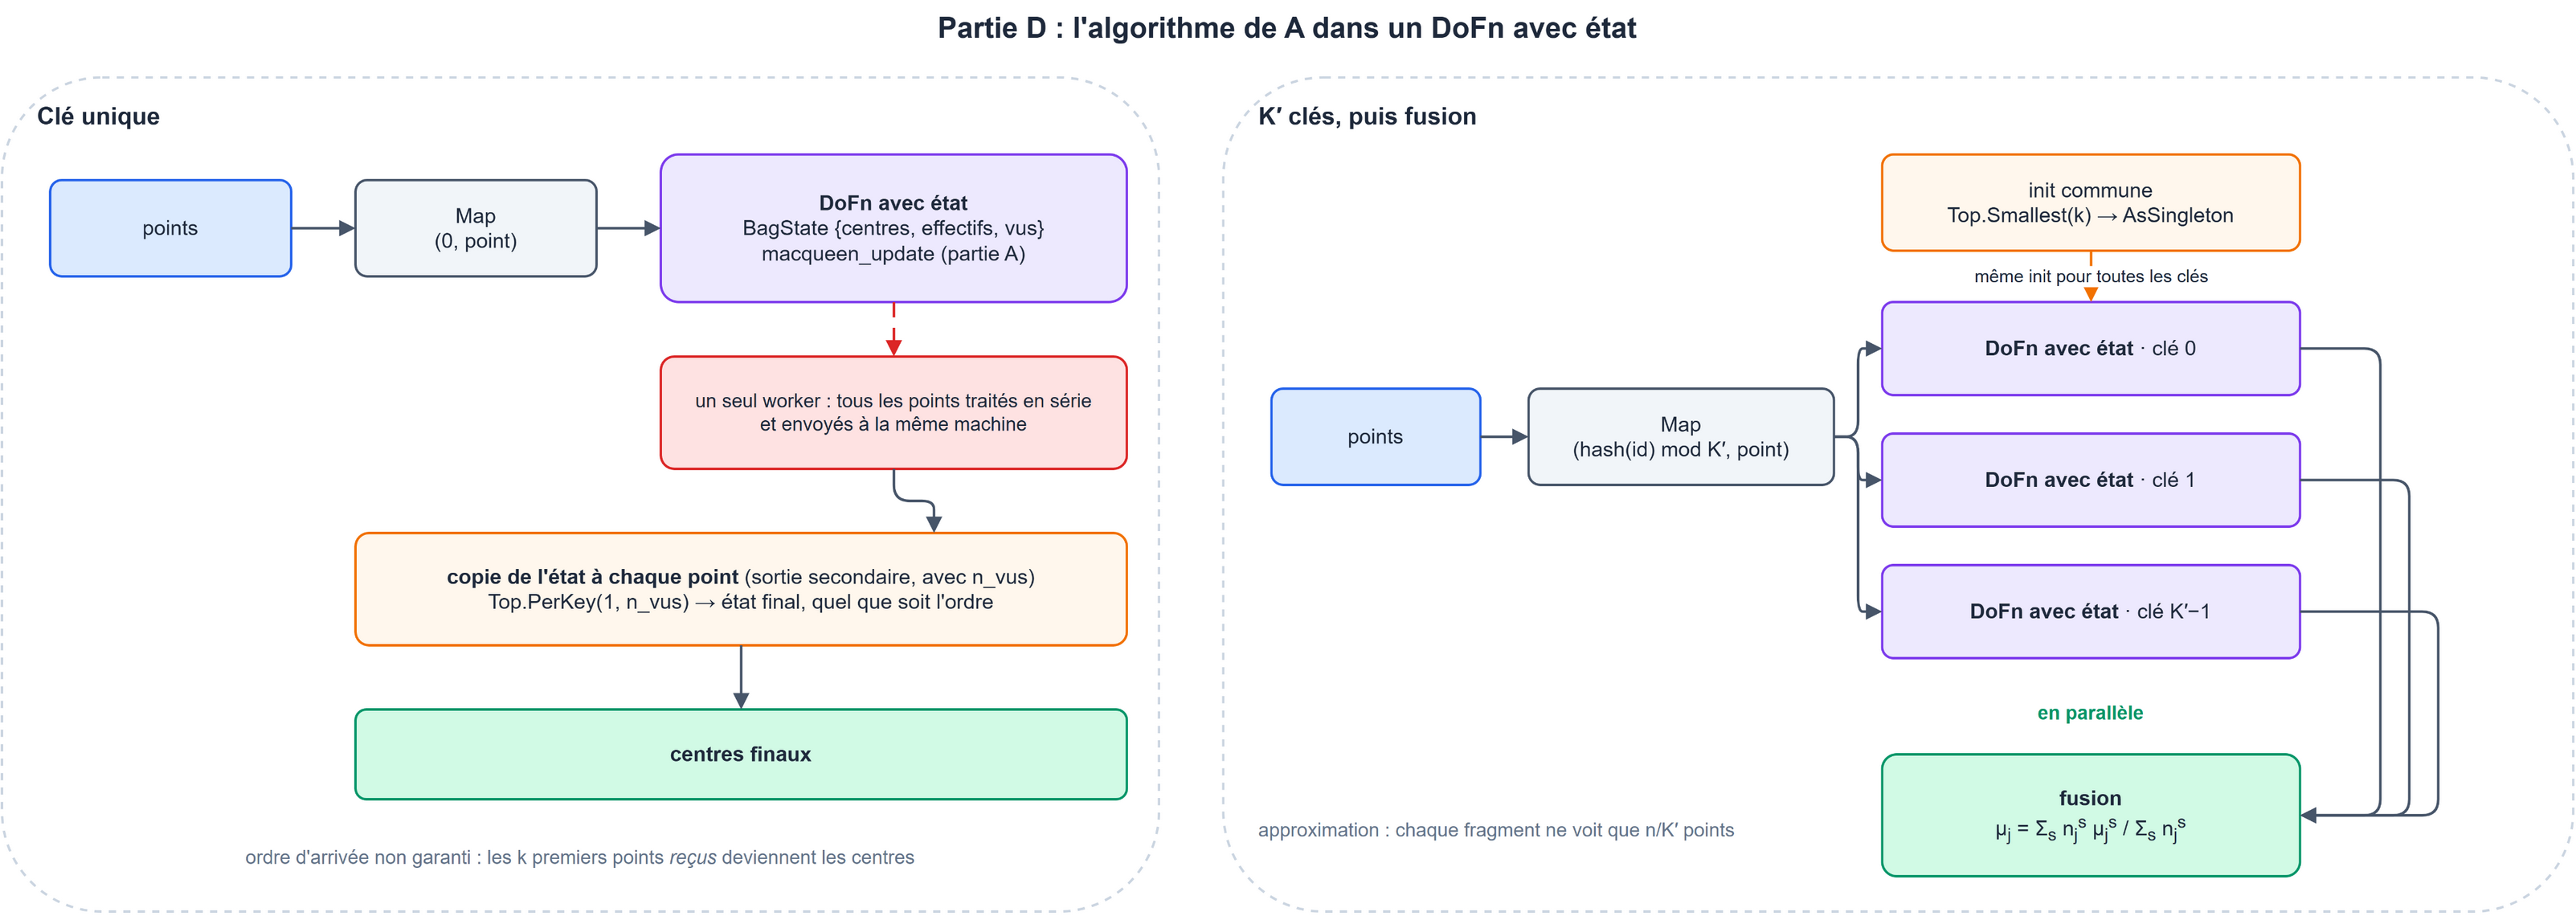

In [23]:
show_diagram("03_beam_stateful")

In [24]:
class SequentialKMeansFn(beam.DoFn):
    MODEL = BagStateSpec("model", PickleCoder())

    def __init__(self, k=K):
        self.k = k

    def process(self, element, init, model=beam.DoFn.StateParam(MODEL)):
        # element = (clé, (id, coordonnées)) ; init = centres communs (side input) ou None.
        key, (pid, x) = element
        current = list(model.read())
        if current:
            state = current[0]
        elif init is not None:                       # initialisation commune (version à plusieurs clés)
            state = {"centers": [list(c) for c in init], "counts": [1] * self.k, "seen": 0}
        else:                                        # les k premiers points reçus deviennent les centres
            state = {"centers": [], "counts": [], "seen": 0}
        x = list(x)
        if len(state["centers"]) < self.k:
            state["centers"].append(x); state["counts"].append(1)
            j = len(state["centers"]) - 1
        else:
            j = macqueen_update(state["centers"], state["counts"], x)
        state["seen"] += 1
        model.clear()
        model.add(state)
        yield key, pid, j                                                    # affectation en ligne
        yield beam.pvalue.TaggedOutput("etat", (key, copy.deepcopy(state)))  # copie de l'état, avec « seen »


def beam_sequential(path, n_keys=1, common_init=False, reshuffle=False, k=K, tag="D"):
    with beam.Pipeline() as p:
        points = read_points(p, path, dim=2)
        if reshuffle:
            points = points | "rebattre" >> beam.Reshuffle()
        if n_keys == 1:
            keyed = points | "clé unique" >> beam.Map(lambda e: (0, e))
        else:
            keyed = points | "K' clés" >> beam.Map(lambda e: (init_key(e[0], n_keys, seed=SEED + 1), e))
        init = None                                   # pas d'init commune : les k premiers points reçus
        if common_init:
            init = beam.pvalue.AsSingleton(
                points | "k plus petits ids" >> beam.combiners.Top.Smallest(k, key=lambda e: e[0])
                       | "coordonnées" >> beam.Map(lambda top: [list(x) for _, x in sorted(top)]))
        out = keyed | "k-means séquentiel" >> beam.ParDo(SequentialKMeansFn(k), init).with_outputs("etat", main="affectations")
        finals = (out.etat | "état le plus avancé" >> beam.combiners.Top.PerKey(1, key=lambda s: s["seen"])
                           | "extraire" >> beam.Map(lambda kv: (kv[0], kv[1][0])))
        write_jsonl(finals, OUT / f"{tag}_final.jsonl", "f")
        write_jsonl(out.affectations, OUT / f"{tag}_assign.jsonl", "a")
    finals = [s for _, s in read_jsonl(OUT / f"{tag}_final.jsonl")]
    assign = {pid: j for _, pid, j in read_jsonl(OUT / f"{tag}_assign.jsonl")}
    return finals, assign


def merge_states(states, init):
    # Fusion des modèles locaux : moyenne pondérée des statistiques suffisantes.
    # Chaque fragment compte une fois le centre initial (effectif 1) : je le retire puis je le remets une seule fois.
    init = np.asarray(init, float)
    S, N = init.copy(), np.ones(len(init))
    for st in states:
        n = np.asarray(st["counts"], float)
        S += n[:, None] * np.asarray(st["centers"]) - init
        N += n - 1
    return S / N[:, None], N

### Clé unique : même calcul que la partie A ?

Avec une seule clé, tous les points passent par le même état, l'un après l'autre. Si Beam les présente dans
l'ordre du fichier, on doit retrouver exactement la partie A : mêmes centres, même affectation « en ligne » pour
chaque point. Je fais le test sur `S` (mélangé) et sur `S_sorted` (trié par classe), puis je recommence en
insérant un `Reshuffle`, qui redistribue les éléments comme le ferait un vrai cluster.

In [25]:
D_rows, D_details = [], {}
for name, path, tagA in (("S mélangé", S_PATH, "S"), ("S trié par classe", S_SORTED_PATH, "Ssorted")):
    A_cent = np.array(json.load(open(OUT / f"A_{tagA}_centers.json"))["centers"])
    A_online = pd.read_csv(OUT / f"A_{tagA}_online.csv").set_index("id").cluster_online.to_dict()
    for reshuffle in (False, True):
        t0 = time.perf_counter()
        finals, assign = beam_sequential(path, reshuffle=reshuffle, tag=f"D_{tagA}_{int(reshuffle)}")
        dt = time.perf_counter() - t0
        st = finals[0]
        same_online = np.mean([assign[pid] == A_online[pid] for pid in A_online])
        D_rows.append({"données": name, "Reshuffle": reshuffle, "points vus": st["seen"],
                       "écart max aux centres de A": float(np.abs(np.array(st["centers"]) - A_cent).max()),
                       "affectations en ligne identiques à A": same_online,
                       "écart à sklearn": center_error(st["centers"], REF_CENTERS_S), "secondes": dt})
D_df = pd.DataFrame(D_rows)
save_result("D_single_key", D_df.round(6).to_dict("records"))
assert (D_df["points vus"] == 200).all()
D_df.round(4)

,données,Reshuffle,points vus,écart max aux centres de A,affectations en ligne identiques à A,écart à sklearn,secondes
0,S mélangé,False,200,0.0,1.0,0.0400,0.5844
1,S mélangé,True,200,0.0,1.0,0.0400,0.6193
2,S trié par classe,False,200,0.0,1.0,1.8481,0.7372
3,S trié par classe,True,200,0.0,1.0,1.8481,0.5540


### Une seule clé : quelles conséquences pour le parallélisme ?

Un état Beam appartient à une clé (et à une fenêtre), et tous les éléments d'une même clé sont traités **en série**
par un seul worker. Avec une clé unique :

- **aucun parallélisme** sur l'étape avec état : un seul worker travaille, quel que soit le nombre de machines, et
  tous les points doivent d'abord lui être envoyés (échange réseau complet vers une seule machine) ;
- ce worker devient un **point chaud** : son débit fixe celui de tout le pipeline ;
- le résultat **dépend de l'ordre** d'arrivée, que Beam ne garantit pas (cours, diapositives 14-15). Les centres
  initiaux sont les $k$ premiers points *reçus*, plus forcément les $k$ premiers du fichier.

L'état lui-même est petit ($O(kd)$), la mémoire n'est donc pas le problème : c'est la sérialisation des calculs.

**Optimisation : K' clés, puis fusion.** Je répartis les points sur $K'$ clés par hachage de leur identifiant.
Chaque clé fait tourner son propre k-means séquentiel, en parallèle des autres. Pour que le cluster $j$ désigne la
même chose dans tous les fragments, ils partent de **la même initialisation**, passée en entrée complémentaire (les
$k$ points de plus petit identifiant, c'est-à-dire la même initialisation que A). À la fin, les modèles locaux sont
fusionnés par moyenne pondérée de leurs statistiques suffisantes, $\mu_j = \sum_s n_j^s \mu_j^s / \sum_s n_j^s$,
ce qui est exact puisque chaque $\mu_j^s$ est une moyenne de points.

Ce que l'on perd : le résultat n'est plus celui de l'algorithme séquentiel sur tout le flux. Chaque fragment voit
$n/K'$ points, et les affectations se font avec des centres locaux.

In [26]:
multi_rows = []
init_A = [x for _, x in zip(range(K), iter_points(S_PATH))]
for n_keys in (1, 2, 4, 8):
    finals, _ = beam_sequential(S_PATH, n_keys=n_keys, common_init=True, tag=f"D_multi{n_keys}")
    merged, N = merge_states(finals, init_A)
    multi_rows.append({"K'": n_keys, "fragments": len(finals), "points vus": sum(s["seen"] for s in finals),
                       "écart aux centres de A": center_error(merged, model_A["centers"]),
                       "écart à sklearn": center_error(merged, REF_CENTERS_S)})
multi_df = pd.DataFrame(multi_rows)
assert (multi_df["points vus"] == 200).all()

time_rows = []
for n_keys in (1, 4):
    t0 = time.perf_counter()
    finals, _ = beam_sequential(L_PATHS[10_000], n_keys=n_keys, common_init=True, tag=f"D_L_{n_keys}")
    merged, _ = merge_states(finals, [x for _, x in zip(range(K), iter_points(L_PATHS[10_000]))])
    time_rows.append({"K'": n_keys, "n": 10_000, "secondes": time.perf_counter() - t0,
                      "taille de l'état (octets, pickle)": len(pickle.dumps(finals[0]))})
save_result("D_multi_key", multi_df.round(6).to_dict("records"))
save_result("D_timing", pd.DataFrame(time_rows).round(3).to_dict("records"))
display(multi_df.round(4)); display(pd.DataFrame(time_rows).round(3))

,K',fragments,points vus,écart aux centres de A,écart à sklearn
0,1,1,200,0.0452,0.0796
1,2,2,200,0.2031,0.2372
2,4,4,200,0.2361,0.2700
3,8,8,200,0.2990,0.3329


,K',n,secondes,"taille de l'état (octets, pickle)"
0,1,10000,1.612,103
1,4,10000,1.475,103


**Ce que je retiens de la partie D.**

- Avec une clé unique, Beam calcule **exactement** la partie A : mêmes centres, mêmes affectations en ligne, sur les
  données mélangées comme sur les données triées. Le `DoFn` applique donc fidèlement l'algorithme séquentiel... à
  l'ordre dans lequel il reçoit les points. Les lignes « trié par classe » le montrent : pour les mêmes 200 points,
  l'ordre d'arrivée fait passer l'écart à `sklearn` de 0,04 à 1,85.
- Sur le runner local, cet ordre est resté celui du fichier, **même après un `Reshuffle`** : un seul processus lit
  le fichier et traite les éléments dans l'ordre. Ce n'est garanti nulle part. Sur un cluster, plusieurs workers liraient
  des morceaux du fichier en parallèle, et le résultat dépendrait de la façon dont leurs sorties s'entrelacent. Un test
  local qui « tombe juste » ne prouve donc pas que le pipeline est déterministe.
- La version à $K'$ clés rend l'étape parallélisable, mais l'écart à A grandit avec $K'$ (tableau ci-dessus). La fusion
  est exacte pour des moyennes, mais chaque fragment garde le biais de son début de passe : ici, les deux centres
  initiaux communs (les deux premiers points du fichier) sont dans le même nuage. Le centre qui doit rejoindre l'autre
  nuage traîne dans sa moyenne les points absorbés au début, et ce biais pèse d'autant plus que le fragment est petit
  ($n/K'$ points). Une meilleure initialisation commune réduirait cet effet.
- Sur une machine, $K'=4$ n'est pas plus rapide que $K'=1$ : le coût fixe du pipeline domine, et il n'y a pas de
  vrais workers séparés.

**Limites.** Il n'y a pas d'ordre global garanti. Les fragments doivent partir de la même initialisation, sinon
les numéros de cluster ne se correspondent plus et la fusion mélangerait des clusters différents. Une alternative
plus robuste serait un k-means pondéré sur les $K' \times k$ centres locaux. Enfin, comme en A, le pas $1/n_j$
empêche de suivre une dérive.

## E. K-means streaming et distribué : la partie B dans Beam

Le flux est simulé avec `TestStream` (cours, diapositives 19 et 45) : chaque point a un horodatage d'événement, et
le batch $t$ correspond à la minute $[60t, 60t+60[$. Le pipeline :

1. `WindowInto(FixedWindows(60))` : une fenêtre fixe par batch ;
2. `GroupByKey` : quand le watermark dépasse la fin de la fenêtre, tous les points du batch sont réunis. L'identifiant
   du batch est le début de la fenêtre ;
3. `WindowInto(GlobalWindows())` : l'état doit vivre d'un batch à l'autre, donc hors des fenêtres fixes ;
4. un `DoFn` avec état garde les $T$ derniers batches et appelle **`streaming_update`, la fonction de la partie B**.

Ce que j'ajoute pour un fonctionnement en conditions réelles :

- les batches sont rangés **par identifiant**, pas par ordre d'arrivée ;
- un batch **déjà vu est ignoré**. Après une panne, le runner peut rejouer un élément ; l'état ne doit pas compter
  deux fois le même batch (idempotence, cours, diapositive 4) ;
- la sortie est **idempotente** elle aussi : un fichier JSON par identifiant de batch, réécrit à l'identique si le
  batch est rejoué ;
- pour le vérifier, j'injecte après le batch 40 des **points en retard** appartenant au batch 5. Leur fenêtre est
  expirée (watermark dépassé, retard autorisé nul), Beam doit donc les écarter.

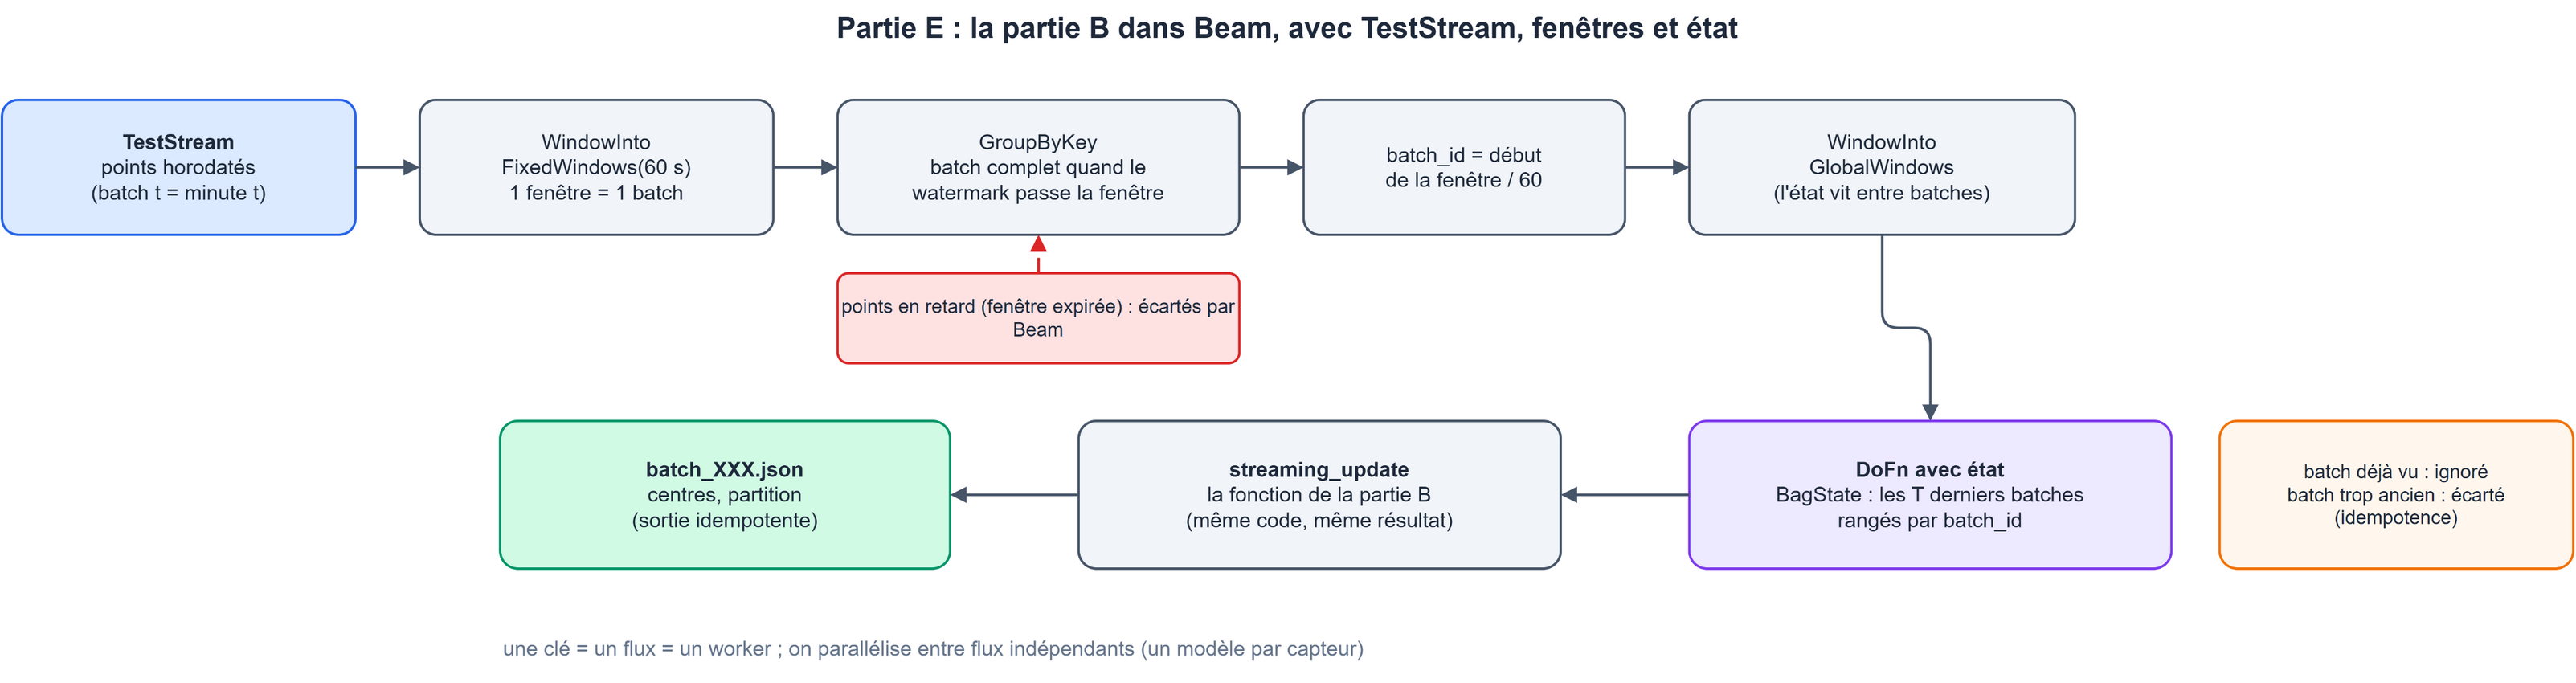

In [27]:
show_diagram("04_beam_streaming")

In [28]:
E_DIR = OUT / "E"

class StreamingKMeansFn(beam.DoFn):
    STATE = BagStateSpec("fenetre", PickleCoder())

    def __init__(self, k, T, r, seed, out_dir):
        self.k, self.T, self.r, self.seed, self.out_dir = k, T, r, seed, str(out_dir)

    def process(self, element, state=beam.DoFn.StateParam(STATE)):
        _, (batch_id, ids, X) = element
        current = list(state.read())
        st = current[0] if current else empty_state()
        new_st, C, P = streaming_update(st, batch_id, np.asarray(X), self.k, self.T, self.r, self.seed)
        with open(os.path.join(self.out_dir, "evenements.log"), "a", encoding="utf-8") as log:
            log.write(f"{batch_id},{'ignoré' if P is None else 'traité'},{len(X)}\n")
        if P is None:
            return
        state.clear()
        state.add(new_st)
        record = {"batch_id": batch_id, "centers": C.tolist(), "window": new_st["ids"],
                  "labels": dict(zip(map(int, ids), map(int, P))),
                  "state_bytes": len(pickle.dumps(new_st))}
        with open(os.path.join(self.out_dir, f"batch_{batch_id:03d}.json"), "w") as f:   # sortie idempotente
            json.dump(record, f)
        yield batch_id, C.tolist()


class BatchFromWindow(beam.DoFn):
    def process(self, element, window=beam.DoFn.WindowParam):
        _, pts = element
        pts = sorted(pts)                                    # ordre par id : le même que dans la partie B
        yield 0, (int(window.start) // 60, [pid for pid, _ in pts], [x for _, x in pts])


def build_test_stream(kind, late_batch=5, late_after=40, n_late=20):
    ts = TestStream()
    for t, (ids, X, y) in enumerate(STREAMS[kind]):
        ts = ts.add_elements([TimestampedValue((int(i), tuple(x)), 60 * t + 0.5 * j)
                              for j, (i, x) in enumerate(zip(ids, X.tolist()))])
        ts = ts.advance_watermark_to(60 * (t + 1))
        if t == late_after:                                  # points en retard, destinés au batch 5
            ts = ts.add_elements([TimestampedValue((10_000_000 + j, (0.0, 0.0)), 60 * late_batch + 1)
                                  for j in range(n_late)])
    return ts.advance_watermark_to_infinity()


def beam_streaming(kind, T=5, r=0.5, seed=SEED):
    if E_DIR.exists():
        shutil.rmtree(E_DIR)
    E_DIR.mkdir(parents=True)
    options = PipelineOptions()
    options.view_as(StandardOptions).streaming = True
    t0 = time.perf_counter()
    with TestPipeline(options=options) as p:
        (p | build_test_stream(kind)
           | "1 batch = 1 fenêtre" >> beam.WindowInto(FixedWindows(60))
           | "clé" >> beam.Map(lambda e: (0, e))
           | "réunir le batch" >> beam.GroupByKey()
           | "id du batch" >> beam.ParDo(BatchFromWindow())
           | "fenêtre globale" >> beam.WindowInto(GlobalWindows())
           | "k-means streaming" >> beam.ParDo(StreamingKMeansFn(K, T, r, seed, E_DIR)))
    dt = time.perf_counter() - t0
    records = [json.load(open(f)) for f in sorted(glob.glob(str(E_DIR / "batch_*.json")))]
    events = pd.read_csv(E_DIR / "evenements.log", names=["batch_id", "action", "points"], encoding="utf-8")
    return records, events, dt

E_records, E_events, E_seconds = beam_streaming("progressive", T=5, r=0.5)
B_ref = drift_runs["progressive"]["B"]["centers"]
E_centers = np.array([rec["centers"] for rec in E_records])
print("batches produits :", len(E_records), "| appels au DoFn :", len(E_events),
      "| points reçus par le batch 5 :", int(E_events.query("batch_id == 5").points.sum()))
print("écart max entre E et B, sur les 60 batches :", float(np.abs(E_centers - B_ref).max()))
assert len(E_records) == N_BATCHES
assert np.allclose(E_centers, B_ref, atol=1e-9), "E doit redonner exactement B"
assert int(E_events.query("batch_id == 5").points.sum()) == BATCH_SIZE, "les points en retard sont écartés"

batches produits : 60 | appels au DoFn : 60 | points reçus par le batch 5 : 100
écart max entre E et B, sur les 60 batches : 0.0


Le test d'idempotence ci-dessous porte directement sur la fonction de mise à jour : je renvoie le batch 30 une
seconde fois, puis un batch plus ancien que toute la fenêtre. L'état ne doit pas bouger.

fenêtre : [26, 27, 28, 29, 30] -> inchangée après un batch rejoué et un batch trop ancien
taille de l'état sérialisé : 10.5 Kio pour T = 5 batches de 100 points ; points en float64 : 7.8 Kio, en float32 : 3.9 Kio


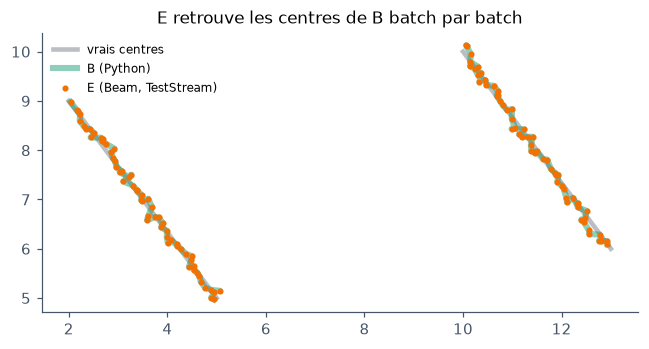

In [29]:
model = StreamingWeightedKMeans(T=5, r=0.5)
for t in range(31):
    model.partial_fit(t, STREAMS["progressive"][t][1])
before = model.state["centers"].copy(), list(model.state["ids"])
C_replay, P_replay = model.partial_fit(30, STREAMS["progressive"][30][1])   # rejoué
C_old, P_old = model.partial_fit(10, STREAMS["progressive"][10][1])          # trop ancien
assert P_replay is None and P_old is None
assert np.array_equal(model.state["centers"], before[0]) and model.state["ids"] == before[1]
print("fenêtre :", model.state["ids"], "-> inchangée après un batch rejoué et un batch trop ancien")

state_bytes = E_records[-1]["state_bytes"]
X_window = np.vstack(model.state["batches"])
save_result("E", {"batches": len(E_records), "dofn_calls": int(len(E_events)), "max_diff_vs_B": float(np.abs(E_centers - B_ref).max()),
                  "late_points_dropped": 20, "late_handling": "écartés par Beam (fenêtre expirée)", "seconds": E_seconds, "state_bytes": state_bytes,
                  "window_float64_bytes": int(X_window.nbytes), "window_float32_bytes": int(X_window.astype(np.float32).nbytes)})
print(f"taille de l'état sérialisé : {state_bytes / 1024:.1f} Kio pour T = 5 batches de 100 points ; "
      f"points en float64 : {X_window.nbytes / 1024:.1f} Kio, en float32 : {X_window.astype(np.float32).nbytes / 1024:.1f} Kio")

fig, ax = plt.subplots(figsize=(6, 4.2))
truth = np.array([drift_centers(t, "progressive") for t in range(N_BATCHES)])
for j in range(K):
    ax.plot(truth[:, j, 0], truth[:, j, 1], color=COL["truth"], lw=3, alpha=.3, label="vrais centres" if j == 0 else None)
    ax.plot(B_ref[:, j, 0], B_ref[:, j, 1], color=COL["B"], lw=4, alpha=.45, label="B (Python)" if j == 0 else None)
    ax.plot(E_centers[:, j, 0], E_centers[:, j, 1], "o", color=COL["E"], ms=3, label="E (Beam, TestStream)" if j == 0 else None)
ax.set_aspect("equal"); ax.legend(fontsize=8); ax.set_title("E retrouve les centres de B batch par batch")
plt.tight_layout(); savefig("E_vs_B"); plt.show()

**Ce que je retiens de la partie E.** La version Beam redonne exactement les centres de la partie B sur les
60 batches, en traitant chaque batch une seule fois. Les points arrivés après l'expiration de leur fenêtre sont
écartés par Beam lui-même : le batch 5 a bien été traité avec ses 100 points, sans les 20 points en retard.

**Mémoire et parallélisme.** L'état contient $T$ batches de points : $O(T\,b\,d)$ par clé, soit quelques Kio ici,
mais il est relu et réécrit en entier à chaque batch. Sur un vrai runner, la taille d'un état par clé est limitée,
et sa lecture coûte des accès au stockage. Stocker les points en `float32`, c'est-à-dire réduire la précision des
valeurs (quantisation, cours, diapositive 61), divise cette taille par deux. Le parallélisme est le même qu'en D :
une clé, un worker. On peut paralléliser **entre** flux indépendants (une clé par capteur ou par client, chacun avec
son modèle), mais pas à l'intérieur d'un même flux, où chaque batch dépend de la partition du précédent. Pour de très
gros batches, on pourrait distribuer le k-means pondéré lui-même avec la partie C, au prix d'un pipeline par batch.

## 6. Synthèse comparative

Le premier tableau est **mesuré** sur les mêmes données `S` (et sur le même flux à dérive progressive pour la
dernière colonne). Le second résume les propriétés **théoriques**. Les temps Beam sont ceux du runner local : ils
comprennent le lancement du pipeline et ne disent rien des performances sur un cluster.

In [30]:
# Partie B (et donc E) sur S : 4 batches de 50 points, T = 4, r = 1 : la fenêtre finit par contenir tout S.
mB = StreamingWeightedKMeans(T=4, r=1.0)
Xs = dfS[["x0", "x1"]].to_numpy()
for t in range(4):
    C_BS, _ = mB.partial_fit(t, Xs[50 * t:50 * (t + 1)])
P_BS = np.argmin(((Xs[:, None] - C_BS[None]) ** 2).sum(-1), 1)

d_state_bytes = time_rows[0]["taille de l'état (octets, pickle)"]
d_final = read_jsonl(OUT / "D_S_0_final.jsonl")[0][1]
P_D = np.argmin(((Xs[:, None] - np.array(d_final["centers"])[None]) ** 2).sum(-1), 1)
e_track = float(np.mean([center_error(c, drift_centers(t, "progressive")) for t, c in enumerate(E_centers)][-10:]))
rows = [
    {"partie": "A séquentiel (Python)", "ARI sur S": stats_A["ari"], "écart à sklearn": center_error(model_A["centers"], REF_CENTERS_S),
     "erreur de suivi, dérive (10 derniers batches)": drift_summary["progressive"]["A"],
     "mémoire mesurée": f"pic {scale_A['pic A (Kio)'].max():.0f} Kio jusqu'à 10⁶ points"},
    {"partie": "B streaming (Python + sklearn)", "ARI sur S": adjusted_rand_score(dfS.label, P_BS), "écart à sklearn": center_error(C_BS, REF_CENTERS_S),
     "erreur de suivi, dérive (10 derniers batches)": drift_summary["progressive"]["B"],
     "mémoire mesurée": f"{stat_B['window_points']} points gardés (T = 5)"},
    {"partie": "C distribué (Beam)", "ARI sur S": C_results[2]["ari"], "écart à sklearn": center_error(C_results[2]["final"], REF_CENTERS_S),
     "erreur de suivi, dérive (10 derniers batches)": np.nan, "mémoire mesurée": "k × d par worker (side input)"},
    {"partie": "D séquentiel avec état (Beam)", "ARI sur S": adjusted_rand_score(dfS.label, P_D),
     "écart à sklearn": center_error(d_final["centers"], REF_CENTERS_S),
     "erreur de suivi, dérive (10 derniers batches)": np.nan, "mémoire mesurée": f"état de {d_state_bytes} octets"},
    {"partie": "E streaming avec état (Beam)", "ARI sur S": adjusted_rand_score(dfS.label, P_BS), "écart à sklearn": center_error(C_BS, REF_CENTERS_S),
     "erreur de suivi, dérive (10 derniers batches)": e_track,
     "mémoire mesurée": f"état de {state_bytes / 1024:.1f} Kio (T = 5)"},
]
synth = pd.DataFrame(rows).set_index("partie")
save_result("synthesis", synth.reset_index().round(4).astype(object).where(synth.reset_index().notna(), None).to_dict("records"))
synth.round(3)

,ARI sur S,écart à sklearn,"erreur de suivi, dérive (10 derniers batches)",mémoire mesurée
partie,,,,
A séquentiel (Python),1.0,0.04,2.304,pic 272 Kio jusqu'à 10⁶ points
B streaming (Python + sklearn),1.0,0.00,0.125,500 points gardés (T = 5)
C distribué (Beam),1.0,0.00,NaN,k × d par worker (side input)
D séquentiel avec état (Beam),1.0,0.04,NaN,état de 103 octets
E streaming avec état (Beam),1.0,0.00,0.125,état de 10.5 Kio (T = 5)


| Partie | Mémoire | Parallélisme | Dépend de l'ordre ? | Suit une dérive ? | Quand la choisir |
|---|---|---|---|---|---|
| A séquentiel | $O(kd)$, constante | aucun : chaque point dépend du précédent | oui | non (le pas $1/n_j$ fige les centres) | une machine, données plus grandes que la mémoire, une ou deux passes |
| B streaming | $O(T\,b\,d)$, bornée | aucun entre batches ; vectorisé dans un batch | un peu (via l'init.) | oui, avec un retard réglé par $T$ et $r$ | flux non stationnaire sur une machine |
| C distribué | données réparties ; $O(kd)$ diffusé à chaque worker | très bon : affectation par point, agrégation combinable | non | non (données fixes) | gros volume fixe, plusieurs machines |
| D avec état | $O(kd)$ par clé | 1 clé = 1 worker ; $K'$ clés = $K'$ workers, puis fusion approchée | oui, et l'ordre n'est pas garanti | non | flux continu, modèle cumulatif, peu de calcul par point |
| E streaming avec état | $O(T\,b\,d)$ par clé | entre flux indépendants seulement | via l'init. ; batches rangés par id | oui | flux non stationnaires, un modèle par clé (capteur, client) |

**Ce qui ressort de l'ensemble.** Aucune version n'est meilleure partout, comme l'annonçait l'énoncé. Le vrai
partage passe entre les algorithmes **dont l'étape de calcul est une agrégation associative** (Lloyd, partie C),
qui se distribuent sans changer le résultat, et ceux **qui portent un état modifié point par point** (A, D) ou batch
par batch (B, E), qui restent séquentiels sur une clé. Beam ne fait pas disparaître cette contrainte. Il la rend
explicite : l'état est attaché à une clé, et l'ordre n'est garanti nulle part.

**Limites de ce travail.**

- Les mesures sont faites sur une machine, avec le runner local : elles montrent les propriétés de mémoire et la
  cohérence des résultats, pas le passage à l'échelle sur un cluster.
- Les données sont simples : deux gaussiennes bien séparées, en dimension 2. Avec des clusters qui se chevauchent,
  la sensibilité à l'initialisation et à l'ordre serait plus forte.
- L'initialisation de C par partition aléatoire est celle de l'énoncé ; une initialisation de type k-means++ ou
  un échantillon de points la remplacerait avantageusement.
- La fusion des fragments en D suppose qu'ils partent de la même initialisation ; je ne l'ai pas testée sur des
  fragments qui divergent.

**Références.**

- Énoncé du projet et cours *Big data*, S. Morbieu, M2 MLSD, Université Paris Cité, 2026-2027.
- J. MacQueen, « Some methods for classification and analysis of multivariate observations », *Proceedings of the
  Fifth Berkeley Symposium on Mathematical Statistics and Probability*, 1967.
- S. Lloyd, « Least squares quantization in PCM », *IEEE Transactions on Information Theory*, 28(2), 1982.
- Documentation Apache Beam (Python SDK) : programming guide (state and timers, windowing, side inputs, combine),
  https://beam.apache.org/documentation/
- Documentation scikit-learn, `sklearn.cluster.KMeans` (`sample_weight`),
  https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html

In [31]:
print("figures :", sorted(p.name for p in FIG.glob("*.png")))
print("résultats : results/results.json", f"({len(RESULTS)} entrées)")

figures : ['A_scaling.png', 'A_validation.png', 'B_drift.png', 'B_grid.png', 'C_convergence.png', 'E_vs_B.png', 'data.png']
résultats : results/results.json (18 entrées)
